In [1]:
import os, time, json, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
 
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_ROOT = "./data"
OUT = "./q2_outputs"          # inside GitHub repo
for sub in ("figures", "gifs", "checkpoints", "results", "tables"):
    os.makedirs(os.path.join(OUT, sub), exist_ok=True)
torch.backends.cudnn.benchmark = True
 
def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
 
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
import platform; print("CPU:", platform.processor() or platform.machine())

torch 2.14.0+cu132 | torchvision 0.29.1+cu132 | device: cuda
GPU: NVIDIA GeForce RTX 2060
CPU: Intel64 Family 6 Model 165 Stepping 2, GenuineIntel


In [2]:
# Data: All 10,000 videos, split by video index
ds = torchvision.datasets.MovingMNIST(root=DATA_ROOT, split=None, download=True)
VIDEOS_U8 = ds.data                     # uint8, (10000, 20, 1, 64, 64)
assert VIDEOS_U8.shape == (10000, 20, 1, 64, 64) and VIDEOS_U8.dtype == torch.uint8
 
TRAIN_U8 = VIDEOS_U8[:8000]             # videos 0-7999
VAL_U8   = VIDEOS_U8[8000:9000]         # videos 8000-8999
TEST_U8  = VIDEOS_U8[9000:10000]        # videos 9000-9999
 
def to_float(v):
    """float32 in [0, 1]. Applied per batch: identical to converting the whole
    dataset up front, but avoids holding 3.3 GB of float32 frames in memory."""
    return v.float() / 255.0
 
TRAIN_DEV = TRAIN_U8.to(DEVICE)
VAL_DEV   = VAL_U8.to(DEVICE)
TEST_DEV  = TEST_U8.to(DEVICE)
print(TRAIN_DEV.shape, VAL_DEV.shape, TEST_DEV.shape)

torch.Size([8000, 20, 1, 64, 64]) torch.Size([1000, 20, 1, 64, 64]) torch.Size([1000, 20, 1, 64, 64])


In [3]:
# Transformations (mirror, rotation, 8 symmetries) and windows
def M(x):
    """Mirror: (Mx)[i, j] = x[i, 63 - j]  (flip the column axis)."""
    return x.flip(-1)
 
def R(x, a=1):
    """Rotation by a quarter-turns anticlockwise."""
    return torch.rot90(x, k=a, dims=(-2, -1))
 
# Group element g = (a, m):  m = 0 -> R^a,  m = 1 -> M R^a  (rotate --> mirror)
G = [(a, m) for m in (0, 1) for a in range(4)]
G_NAMES = {(a, m): ("M" if m else "") + (f"R^{a}" if (a or not m) else "") for a, m in G}
 
def apply_g(x, g):
    a, m = g
    y = R(x, a)
    return M(y) if m else y
 
def invert_g(x, g):
    """R^a has inverse R^-a; every M R^a is its own inverse."""
    a, m = g
    return apply_g(x, g) if m else R(x, -a)
 
N_FRAMES = 20
STARTS_NORMAL = {1: list(range(1, 12))}                                     # models A, B
STARTS_AUG = {1: list(range(1, 15)), 2: list(range(1, 9)), 3: [1, 2]}       # models C, D
 
def make_windows(videos, t, k):
    """videos: (B, 20, C, H, W).  t, k: ints or LongTensors of shape (B,), frames 1-based.
    Returns X (B,5,C,H,W), Y (B,5,C,H,W) with non-existent targets zero-filled,
    and valid (B,5) bool marking target frames that exist (frame number <= 20)."""
    B, dev = videos.shape[0], videos.device
    t = torch.as_tensor(t, device=dev).long().expand(B) if not torch.is_tensor(t) or t.dim() == 0 \
        else t.to(dev).long()
    k = torch.as_tensor(k, device=dev).long().expand(B) if not torch.is_tensor(k) or k.dim() == 0 \
        else k.to(dev).long()
    j = torch.arange(5, device=dev)
    in_idx = (t[:, None] - 1) + j[None] * k[:, None]           # 0-based frame indices
    out_idx = (t[:, None] - 1) + (5 + j[None]) * k[:, None]
    valid = out_idx <= N_FRAMES - 1
    assert (in_idx <= N_FRAMES - 1).all(), "all five input frames must exist"
    assert valid[:, :2].all(), "at least two target frames must exist"
    b = torch.arange(B, device=dev)[:, None]
    X = videos[b, in_idx]
    Y = videos[b, out_idx.clamp(max=N_FRAMES - 1)]
    Y = Y * valid[..., None, None, None].to(Y.dtype)
    return X, Y, valid

In [4]:
# Table 1: checks on synthetic tensors (uses same functions as experiments)
def fmt(v):
    """3 significant figures; scientific notation below 1e-3."""
    v = float(v)
    if v == 0:
        return "0"
    if abs(v) < 1e-3:
        return f"{v:.2e}"
    s = f"{v:#.3g}"
    return s[:-1] if s.endswith(".") else s
 
def latex_table(header, rows, caption, label):
    cols = "l" * len(header)
    lines = [r"\begin{table}[H]", r"\centering\small", rf"\begin{{tabular}}{{{cols}}}", r"\toprule",
             " & ".join(header) + r" \\", r"\midrule"]
    lines += [" & ".join(str(c) for c in r) + r" \\" for r in rows]
    lines += [r"\bottomrule", r"\end{tabular}", rf"\caption{{{caption}}}", rf"\label{{{label}}}", r"\end{table}"]
    return "\n".join(lines)
 
torch.manual_seed(0); x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64); p[7, 0, 10, 20] = 1
 
def maxdiff(a, b):
    return (a - b).abs().max().item()
 
def bright(v):
    f, _, r, c = (v == 1).nonzero()[0].tolist()
    return f"({f}, {r}, {c})"
 
rows = []
lhs = M(M(x));      rows.append(["(a) $\\max|M(M(x)) - x|$", "0", f"{maxdiff(lhs, x):g} (torch.equal: {torch.equal(lhs, x)})"])
lhs = R(x, 4);      rows.append(["(b) $\\max|R^4(x) - x|$", "0", f"{maxdiff(lhs, x):g} (torch.equal: {torch.equal(lhs, x)})"])
lhs = M(R(M(x)))    # MRM(x): mirror, then rotate, then mirror
rhs = R(x, -1)
rows.append(["(c) $\\max|MRM(x) - R^{-1}(x)|$", "0", f"{maxdiff(lhs, rhs):g} (torch.equal: {torch.equal(lhs, rhs)})"])
rows.append(["(d) bright pixel of $M(p)$", "(7, 10, 43)", bright(M(p))])
rows.append(["(e) bright pixel of $R(p)$", "(7, 43, 10)", bright(R(p))])
 
numbered = torch.arange(1, 21, dtype=torch.float32).view(20, 1, 1, 1).expand(20, 1, 64, 64).clone()
expected = {1: "1--5 / 6--10", 2: "1, 3, 5, 7, 9 / 11, 13, 15, 17, 19", 3: "1, 4, 7, 10, 13 / 16, 19"}
for label, k in (("(f)", 1), ("(g)", 2), ("(h)", 3)):
    X, Y, valid = make_windows(numbered[None], 1, k)
    xin = [int(v) for v in X[0, :, 0, 0, 0].tolist()]
    yout = [int(v) for v in Y[0, valid[0], 0, 0, 0].tolist()]
    # sanity: every pixel of a returned frame carries the same frame number
    assert (X[0] == X[0, :, :1, :1, :1]).all() and (Y[0, valid[0]] == Y[0, valid[0], :1, :1, :1]).all()
    rows.append([f"{label} {k}$\\times$ input / target frames", expected[k],
                 ", ".join(map(str, xin)) + " / " + ", ".join(map(str, yout))])
 
for r in rows:
    print(f"{r[0]:<45} expected {r[1]:<40} yours {r[2]}")
assert all(r[2].startswith("0 ") for r in rows[:3]), "checks (a)-(c) failed"
assert rows[3][2] == "(7, 10, 43)" and rows[4][2] == "(7, 43, 10)", "checks (d)-(e) failed"
tex = latex_table(["Check", "Expected", "Yours"], rows,
                  "Implementation checks on synthetic tensors.", "tab:q2-1")
open(f"{OUT}/tables/table1.tex", "w").write(tex)

(a) $\max|M(M(x)) - x|$                       expected 0                                        yours 0 (torch.equal: True)
(b) $\max|R^4(x) - x|$                        expected 0                                        yours 0 (torch.equal: True)
(c) $\max|MRM(x) - R^{-1}(x)|$                expected 0                                        yours 0 (torch.equal: True)
(d) bright pixel of $M(p)$                    expected (7, 10, 43)                              yours (7, 10, 43)
(e) bright pixel of $R(p)$                    expected (7, 43, 10)                              yours (7, 43, 10)
(f) 1$\times$ input / target frames           expected 1--5 / 6--10                             yours 1, 2, 3, 4, 5 / 6, 7, 8, 9, 10
(g) 2$\times$ input / target frames           expected 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19       yours 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19
(h) 3$\times$ input / target frames           expected 1, 4, 7, 10, 13 / 16, 19                 yours 1, 4, 7, 10, 13 / 16, 19


789

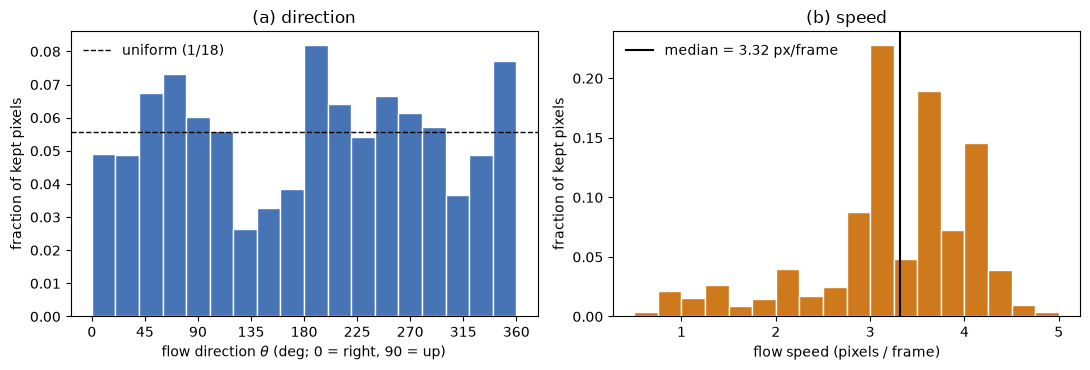

Pixels kept: 103050   median speed: 3.318 px/frame  -> 2x: 6.64, 3x: 9.95 px/frame
speed percentiles 10/25/75/90/99: [2.14 3.   3.89 4.12 4.67]
direction histogram (fraction per 20-deg bin): [0.049  0.0488 0.0675 0.0731 0.0602 0.0561 0.0263 0.0326 0.0384 0.082
 0.0642 0.0541 0.0666 0.0614 0.0571 0.0366 0.0487 0.0772]
max / min bin relative to uniform: 1.475 0.474
TV distance histogram vs its mirror image (theta -> 180 - theta): 0.1322
TV distance histogram vs its 90-deg rotation (theta -> theta + 90): 0.2


In [5]:
# Figure 1: optical-flow statistics of first 50 training videos
import cv2
 
angles, speeds = [], []
for v in range(50):
    # The stored uint8 frames are exactly round(255 * x) for the float frames x in [0, 1].
    vid = TRAIN_U8[v, :, 0].numpy()
    for s in range(19):                                  # pairs (x_s, x_{s+1}), s = 1..19
        prev, nxt = vid[s], vid[s + 1]
        flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[..., 0], flow[..., 1]
        mag = np.sqrt(dx ** 2 + dy ** 2)
        keep = (prev > 51) & (nxt > 51) & (mag > 0.5)    # intensity > 0.2 in both frames
        angles.append(np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360.0)
        speeds.append(mag[keep])
angles, speeds = np.concatenate(angles), np.concatenate(speeds)
N_KEPT, MED_SPEED = len(speeds), float(np.median(speeds))
w = np.full(N_KEPT, 1.0 / N_KEPT)
 
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
dir_bins = np.arange(0, 361, 20)
h_dir, _, _ = ax[0].hist(angles, bins=dir_bins, weights=w, color="#4774b5", edgecolor="white")
ax[0].axhline(1 / 18, color="k", ls="--", lw=1, label="uniform (1/18)")
ax[0].set(xlabel=r"flow direction $\theta$ (deg; 0 = right, 90 = up)", ylabel="fraction of kept pixels",
          xticks=np.arange(0, 361, 45), title="(a) direction")
ax[0].legend(frameon=False)
speed_bins = np.arange(0.5, np.percentile(speeds, 99.5) + 0.25, 0.25)
ax[1].hist(speeds, bins=speed_bins, weights=w, color="#ce791c", edgecolor="white")
ax[1].axvline(MED_SPEED, color="k", lw=1.5, label=f"median = {MED_SPEED:.2f} px/frame")
ax[1].set(xlabel="flow speed (pixels / frame)", ylabel="fraction of kept pixels", title="(b) speed")
ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{OUT}/figures/fig1_flow.pdf", bbox_inches="tight"); plt.show()
 
# Numbers needed for the caption and for Q2.1
def tv_distance(a1, a2):
    h1, _ = np.histogram(a1, bins=dir_bins); h2, _ = np.histogram(a2, bins=dir_bins)
    return 0.5 * np.abs(h1 / h1.sum() - h2 / h2.sum()).sum()
print(f"Pixels kept: {N_KEPT}   median speed: {MED_SPEED:.3f} px/frame  "
      f"-> 2x: {2*MED_SPEED:.2f}, 3x: {3*MED_SPEED:.2f} px/frame")
print("speed percentiles 10/25/75/90/99:", np.round(np.percentile(speeds, [10, 25, 75, 90, 99]), 2))
print("direction histogram (fraction per 20-deg bin):", np.round(h_dir, 4))
print("max / min bin relative to uniform:", round(h_dir.max() * 18, 3), round(h_dir.min() * 18, 3))
print("TV distance histogram vs its mirror image (theta -> 180 - theta):", round(tv_distance(angles, (180 - angles) % 360), 4))
print("TV distance histogram vs its 90-deg rotation (theta -> theta + 90):", round(tv_distance(angles, (angles + 90) % 360), 4))

In [6]:
# ConvLSTM forecaster (model A; also configurable for model D)
class ConvLSTMCell(nn.Module):
    def __init__(self, cin, hidden, kernel=3, dilation=1):
        super().__init__()
        self.hidden = hidden
        pad = dilation * (kernel // 2)                    # "same" size; = 1 for 3x3, dilation 1
        self.conv = nn.Conv2d(cin + hidden, 4 * hidden, kernel, stride=1, padding=pad,
                              dilation=dilation, bias=True)
 
    def forward(self, u, state):
        h, c = state
        i, f, o, g = self.conv(torch.cat([u, h], dim=1)).chunk(4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c
 
 
class ConvLSTMForecaster(nn.Module):
    def __init__(self, patch=4, hidden=(64, 64), kernels=(3, 3), dilations=(1, 1)):
        super().__init__()
        self.patch, self.hidden = patch, tuple(hidden)
        cells, cin = [], patch * patch
        for h, k, d in zip(hidden, kernels, dilations):
            cells.append(ConvLSTMCell(cin, h, k, d)); cin = h
        self.cells = nn.ModuleList(cells)
        self.out = nn.Conv2d(hidden[-1], patch * patch, 1, bias=True)
 
    def step(self, frame, states):
        u = F.pixel_unshuffle(frame, self.patch)
        new = []
        for cell, st in zip(self.cells, states):
            h, c = cell(u, st)
            new.append((h, c)); u = h
        return torch.sigmoid(F.pixel_shuffle(self.out(u), self.patch)), new
 
    def forward(self, X):
        """X: (B, 5, 1, 64, 64) -> Y_hat: (B, 5, 1, 64, 64). 9-step rollout, no teacher forcing."""
        B, _, _, H, W = X.shape
        s = H // self.patch
        states = [(X.new_zeros(B, h, s, s), X.new_zeros(B, h, s, s)) for h in self.hidden]
        preds, pred = [], None
        for tau in range(1, 10):
            u = X[:, tau - 1] if tau <= 5 else pred       # own prediction fed back (gradients flow)
            pred, states = self.step(u, states)
            if tau >= 5:
                preds.append(pred)                        # outputs of steps 5..9 = x_hat_6..x_hat_10
        return torch.stack(preds, dim=1)
 
 
SPECS = {"A": dict(patch=4, hidden=(64, 64), kernels=(3, 3), dilations=(1, 1))}
 
def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
 
PARAMS_A = n_params(ConvLSTMForecaster(**SPECS["A"]))
print("model A trainable parameters:", PARAMS_A)
assert PARAMS_A == 480_784

model A trainable parameters: 480784


In [7]:
# Training protocol (shared by all learned models)
def sample_windows(B, gen, speed_aug):
    if not speed_aug:
        k = torch.ones(B, dtype=torch.long)
        t = torch.randint(1, 12, (B,), generator=gen)                       # t in {1..11}
    else:
        k = torch.randint(1, 4, (B,), generator=gen)                        # k uniform in {1,2,3}
        n_starts = torch.tensor([0, 14, 8, 2])[k]                           # allowed starts per k
        t = 1 + (torch.rand(B, generator=gen) * n_starts).long()            # t uniform over them
    return t, k
 
def random_symmetry(X, Y, gen):
    """Draw g uniformly from the 8 elements of G per window; same g on input and target."""
    gi = torch.randint(0, 8, (X.shape[0],), generator=gen).to(X.device)
    Xo, Yo = X.clone(), Y.clone()
    for i, g in enumerate(G):
        sel = gi == i
        if sel.any():
            Xo[sel], Yo[sel] = apply_g(X[sel], g), apply_g(Y[sel], g)
    return Xo, Yo
 
def per_video_loss(pred, Y, valid):
    """Squared error averaged over pixels and the available target frames of each video."""
    se = ((pred - Y) ** 2).mean(dim=(2, 3, 4))                              # (B, 5)
    v = valid.to(se.dtype)
    return (se * v).sum(1) / v.sum(1)
 
@torch.no_grad()
def val_E5(model, bs=100):
    """Validation monitoring only: E^(5) at 1x, t = 1."""
    model.eval(); tot = 0.0
    for s in range(0, len(VAL_DEV), bs):
        X, Y, _ = make_windows(VAL_DEV[s:s + bs], 1, 1)
        tot += ((model(to_float(X)) - to_float(Y)) ** 2).mean(dim=(1, 2, 3, 4)).sum().item()
    model.train()
    return tot / len(VAL_DEV)
 
def ckpt_path(name, seed):
    return f"{OUT}/checkpoints/{name}_s{seed}.pt"
 
def train_model(name, spec, seed, speed_aug=False, sym_aug=False, epochs=30, bs=32, lr=1e-3):
    path = ckpt_path(name, seed)
    if os.path.exists(path):
        print(f"{name} seed {seed}: checkpoint found, skipping training")
        return load_model(name, seed)
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = ConvLSTMForecaster(**spec).to(DEVICE)                           # default PyTorch init
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    gen = torch.Generator().manual_seed(seed)       # shuffling, windows, augmentation
    N, log = len(TRAIN_DEV), {"epoch_time": [], "train_loss": [], "val_E5": []}
    model.train()
    for ep in range(epochs):
        sync(); t0 = time.perf_counter()
        perm, total = torch.randperm(N, generator=gen), torch.zeros((), device=DEVICE)
        for s in range(0, N, bs):
            idx = perm[s:s + bs].to(DEVICE)
            t, k = sample_windows(len(idx), gen, speed_aug)
            X, Y, valid = make_windows(TRAIN_DEV[idx], t, k)
            X, Y = to_float(X), to_float(Y)
            if sym_aug:
                X, Y = random_symmetry(X, Y, gen)
            loss = per_video_loss(model(X), Y, valid).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            total += loss.detach() * len(idx)
        sync(); log["epoch_time"].append(time.perf_counter() - t0)         # training pass only
        log["train_loss"].append(total.item() / N)
        log["val_E5"].append(val_E5(model))                                # not timed
        print(f"{name} s{seed} ep {ep+1:2d}  train {log['train_loss'][-1]:.5f}  "
              f"val E5 {log['val_E5'][-1]:.5f}  {log['epoch_time'][-1]:.1f}s")
    torch.save({"state_dict": model.state_dict(), "spec": spec, "seed": seed, "speed_aug": speed_aug,
                "sym_aug": sym_aug, "log": log}, path)
    return model.eval()
 
def load_model(name, seed):
    ck = torch.load(ckpt_path(name, seed), map_location=DEVICE)
    model = ConvLSTMForecaster(**ck["spec"]).to(DEVICE)
    model.load_state_dict(ck["state_dict"])
    return model.eval()
 
def train_time_per_epoch(name, seed):
    return float(np.mean(torch.load(ckpt_path(name, seed), map_location="cpu")["log"]["epoch_time"]))

In [8]:
# Train model A (seeds 0 and 1)
for seed in (0, 1):
    train_model("A", SPECS["A"], seed, speed_aug=False, sym_aug=False)

A seed 0: checkpoint found, skipping training
A seed 1: checkpoint found, skipping training


In [9]:
# Evaluation utilities (test split only)
@torch.no_grad()
def predict(f, X, bs=32):
    return torch.cat([f(X[s:s + bs]) for s in range(0, len(X), bs)])
 
def blank(X):
    return torch.zeros_like(X)
 
def copy_last(X):
    return X[:, -1:].expand_as(X).contiguous()
 
def test_windows(k=1, t=1):
    X, Y, valid = make_windows(TEST_DEV, t, k)
    return to_float(X), to_float(Y), valid
 
def horizon_mse(P, Y):
    """(N, 5): per-video MSE over the 64x64 pixels of each forecast horizon."""
    return ((P - Y) ** 2).mean(dim=(2, 3, 4))
 
def predictors(name):
    """Seed-indexed callables for a model name; Blank/Copy-last are deterministic (one entry)."""
    if name == "Blank":
        return {None: blank}
    if name == "Copy-last":
        return {None: copy_last}
    return {s: load_model(name, s) for s in (0, 1)}
 
def summarize(values):
    """values: dict seed -> number.  'mean (seed 0, seed 1)' or a single value."""
    if None in values:
        return fmt(values[None])
    v = [values[0], values[1]]
    return f"{fmt(np.mean(v))} ({fmt(v[0])}, {fmt(v[1])})"

In [10]:
# Table 2: model A vs Blank and Copy-last at 1x, t = 1
X1, Y1, _ = test_windows(1)
table2, res2 = [], {}
for name in ("A", "Blank", "Copy-last"):
    per = {}
    for seed, f in predictors(name).items():
        h = horizon_mse(predict(f, X1), Y1).mean(0).cpu().numpy()          # (5,) averaged over videos
        per[seed] = h
    res2[name] = {str(s): v.tolist() for s, v in per.items()}
    cols = [summarize({s: v[i] for s, v in per.items()}) for i in range(5)]
    cols.append(summarize({s: v.mean() for s, v in per.items()}))
    cols.append(f"{PARAMS_A:,}" if name == "A" else "0")
    table2.append([name] + cols)
    print(name, cols)
json.dump(res2, open(f"{OUT}/results/table2.json", "w"), indent=1)
tex = latex_table(["Model"] + [f"MSE$_{h}$" for h in range(1, 6)] + ["$E^{(5)}$", "Params"], table2,
                  "Test-set error of model A and the reference predictors (1$\\times$, $t=1$). "
                  "Learned models: mean (seed 0, seed 1).", "tab:q2-2")
open(f"{OUT}/tables/table2.tex", "w").write(tex); print(tex)

A ['0.0170 (0.0174, 0.0166)', '0.0204 (0.0210, 0.0199)', '0.0228 (0.0235, 0.0221)', '0.0245 (0.0253, 0.0237)', '0.0262 (0.0269, 0.0254)', '0.0222 (0.0228, 0.0215)', '480,784']
Blank ['0.0426', '0.0426', '0.0426', '0.0425', '0.0425', '0.0426', '0']
Copy-last ['0.0492', '0.0604', '0.0669', '0.0708', '0.0732', '0.0641', '0']
\begin{table}[H]
\centering\small
\begin{tabular}{llllllll}
\toprule
Model & MSE$_1$ & MSE$_2$ & MSE$_3$ & MSE$_4$ & MSE$_5$ & $E^{(5)}$ & Params \\
\midrule
A & 0.0170 (0.0174, 0.0166) & 0.0204 (0.0210, 0.0199) & 0.0228 (0.0235, 0.0221) & 0.0245 (0.0253, 0.0237) & 0.0262 (0.0269, 0.0254) & 0.0222 (0.0228, 0.0215) & 480,784 \\
Blank & 0.0426 & 0.0426 & 0.0426 & 0.0425 & 0.0425 & 0.0426 & 0 \\
Copy-last & 0.0492 & 0.0604 & 0.0669 & 0.0708 & 0.0732 & 0.0641 & 0 \\
\bottomrule
\end{tabular}
\caption{Test-set error of model A and the reference predictors (1$\times$, $t=1$). Learned models: mean (seed 0, seed 1).}
\label{tab:q2-2}
\end{table}


In [11]:
# Overlap detector (used to pick videos for Figures 2 and 5)
from scipy import ndimage
 
def n_blobs(frame, thr=0.2):
    return ndimage.label(frame > thr)[1]
 
def overlaps(video_u8, frames_1based):
    """True if the two digits appear merged (fewer than 2 blobs) in any of the listed frames."""
    v = to_float(video_u8[:, 0]).cpu().numpy()
    return any(n_blobs(v[f - 1]) < 2 for f in frames_1based)
 
frames_1x = list(range(1, 11))
over = [i for i in range(len(TEST_U8)) if overlaps(TEST_U8[i], frames_1x)]
clean = [i for i in range(len(TEST_U8)) if not overlaps(TEST_U8[i], frames_1x)]
print(f"{len(over)} test videos with overlap in frames 1-10, e.g. {over[:10]}")
print(f"{len(clean)} without, e.g. {clean[:10]}")

802 test videos with overlap in frames 1-10, e.g. [0, 1, 2, 3, 4, 5, 6, 8, 9, 10]
198 without, e.g. [7, 12, 14, 21, 26, 29, 37, 38, 39, 44]


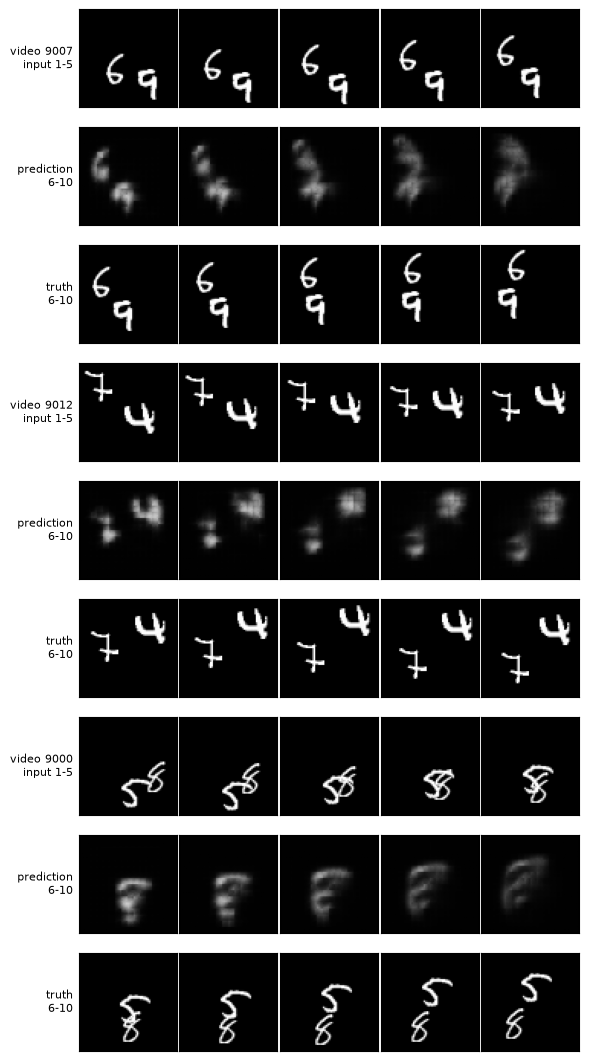

Figure 2 videos (dataset index): [9007, 9012, 9000] | overlapping: [9000]


In [12]:
# Figure 2: input, prediction and ground truth for three test videos (seed-0 model A)
def show_rows(rows, row_labels, path, col_titles=None, figsize_per=1.15):
    """rows: list of lists of 2-D arrays (None = blank cell)."""
    nr, nc = len(rows), max(len(r) for r in rows)
    fig, axes = plt.subplots(nr, nc, figsize=(figsize_per * nc, figsize_per * nr + 0.3), squeeze=False)
    for r, row in enumerate(rows):
        for c in range(nc):
            ax = axes[r, c]; ax.set_xticks([]); ax.set_yticks([])
            img = row[c] if c < len(row) else None
            if img is None:
                ax.axis("off")
            else:
                ax.imshow(img, cmap="gray", vmin=0, vmax=1)
            if c == 0:
                ax.set_ylabel(row_labels[r], rotation=0, ha="right", va="center", fontsize=8)
            if r == 0 and col_titles:
                ax.set_title(col_titles[c], fontsize=8)
    fig.tight_layout(pad=0.2); fig.savefig(path, bbox_inches="tight", dpi=150); plt.show()
 
FIG2_VIDEOS = [clean[0], clean[1], over[0]]          # change these indices if you prefer others
mA = load_model("A", 0)
rows, labels = [], []
for i in FIG2_VIDEOS:
    X, Y, _ = make_windows(TEST_DEV[i:i + 1], 1, 1)
    X, Y = to_float(X), to_float(Y)
    P = predict(mA, X)
    rows += [[X[0, j, 0].cpu() for j in range(5)], [P[0, j, 0].cpu() for j in range(5)],
             [Y[0, j, 0].cpu() for j in range(5)]]
    labels += [f"video {9000+i}\ninput 1-5", "prediction\n6-10", "truth\n6-10"]
show_rows(rows, labels, f"{OUT}/figures/fig2_examples.pdf")
print("Figure 2 videos (dataset index):", [9000 + i for i in FIG2_VIDEOS],
      "| overlapping:", [9000 + i for i in FIG2_VIDEOS if i in over])

In [13]:
# Figure 1 stays on the first 50 videos => supporting check for Q2.1 only.
def flow_angles(video_ids):
    out = []
    for v in video_ids:
        vid = TRAIN_U8[v, :, 0].numpy()
        for s in range(19):
            prev, nxt = vid[s], vid[s + 1]
            flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
            dx, dy = flow[..., 0], flow[..., 1]
            keep = (prev > 51) & (nxt > 51) & (np.sqrt(dx**2 + dy**2) > 0.5)
            out.append(np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360.0)
    return np.concatenate(out)
 
a_first25, a_second25 = flow_angles(range(25)), flow_angles(range(25, 50))
print("noise level: TV(first 25 videos, next 25 videos) =", round(tv_distance(a_first25, a_second25), 4))
a500 = flow_angles(range(500))
h500, _ = np.histogram(a500, bins=dir_bins); h500 = h500 / h500.sum()
print("500 videos: max / min bin relative to uniform:", round(h500.max() * 18, 3), round(h500.min() * 18, 3))
print("500 videos: TV vs mirror:", round(tv_distance(a500, (180 - a500) % 360), 4),
      "| TV vs 90-deg rotation:", round(tv_distance(a500, (a500 + 90) % 360), 4))

noise level: TV(first 25 videos, next 25 videos) = 0.1835
500 videos: max / min bin relative to uniform: 1.269 0.682
500 videos: TV vs mirror: 0.0971 | TV vs 90-deg rotation: 0.1238


In [14]:
# Improved LaTeX tables (wide tables scaled to text width) + Table 3
def latex_table(header, rows, caption, label):
    cols = "l" * len(header)
    lines = [r"\begin{table}[H]", r"\centering\small", r"\resizebox{\linewidth}{!}{%",
             rf"\begin{{tabular}}{{{cols}}}", r"\toprule", " & ".join(header) + r" \\", r"\midrule"]
    lines += [" & ".join(str(c) for c in r) + r" \\" for r in rows]
    lines += [r"\bottomrule", r"\end{tabular}}", rf"\caption{{{caption}}}", rf"\label{{{label}}}", r"\end{table}"]
    return "\n".join(lines)
 
@torch.no_grad()
def symmetry_eval(f, X, Y):
    """Per-video E5, C_M, E_M, C_R, E_R at 1x, t = 1 (pixels and 5 horizons averaged per video)."""
    PX = predict(f, X)
    out = {"E5": ((PX - Y) ** 2).mean(dim=(1, 2, 3, 4))}
    preds = {"X": PX}
    for name, T in (("M", M), ("R", R)):
        PTX = predict(f, T(X))
        out["C" + name] = ((PTX - T(PX)) ** 2).mean(dim=(1, 2, 3, 4))
        out["E" + name] = ((PTX - T(Y)) ** 2).mean(dim=(1, 2, 3, 4))
        preds[name] = PTX
    return {k: v.cpu() for k, v in out.items()}, preds
 
def table_row(name, per_seed, keys):
    return [name] + [summarize({s: float(v[k].mean()) for s, v in per_seed.items()}) for k in keys]
 
X1, Y1, _ = test_windows(1)
SYM = {}                                   # SYM[model][seed] = per-video metrics
for name in ("A", "Blank", "Copy-last"):
    SYM[name] = {s: symmetry_eval(f, X1, Y1)[0] for s, f in predictors(name).items()}
torch.save(SYM, f"{OUT}/results/sym_A_blank_copy.pt")
 
keys3 = ["E5", "CM", "EM", "CR", "ER"]
table3 = [table_row(n, SYM[n], keys3) for n in ("A", "Blank", "Copy-last")]
for r in table3: print(r)
tex = latex_table(["Model", "$E^{(5)}$", "$C_M$", "$E_M$", "$C_R$", "$E_R$"], table3,
                  "Consistency gaps and transformed errors (1$\\times$, $t=1$, test set). "
                  "Learned models: mean (seed 0, seed 1).", "tab:q2-3")
open(f"{OUT}/tables/table3.tex", "w").write(tex); print(tex)

['A', '0.0222 (0.0228, 0.0215)', '0.00168 (0.00151, 0.00186)', '0.0228 (0.0234, 0.0223)', '0.00272 (0.00227, 0.00318)', '0.0238 (0.0242, 0.0234)']
['Blank', '0.0426', '0', '0.0426', '0', '0.0426']
['Copy-last', '0.0641', '0', '0.0641', '0', '0.0641']
\begin{table}[H]
\centering\small
\resizebox{\linewidth}{!}{%
\begin{tabular}{llllll}
\toprule
Model & $E^{(5)}$ & $C_M$ & $E_M$ & $C_R$ & $E_R$ \\
\midrule
A & 0.0222 (0.0228, 0.0215) & 0.00168 (0.00151, 0.00186) & 0.0228 (0.0234, 0.0223) & 0.00272 (0.00227, 0.00318) & 0.0238 (0.0242, 0.0234) \\
Blank & 0.0426 & 0 & 0.0426 & 0 & 0.0426 \\
Copy-last & 0.0641 & 0 & 0.0641 & 0 & 0.0641 \\
\bottomrule
\end{tabular}}
\caption{Consistency gaps and transformed errors (1$\times$, $t=1$, test set). Learned models: mean (seed 0, seed 1).}
\label{tab:q2-3}
\end{table}


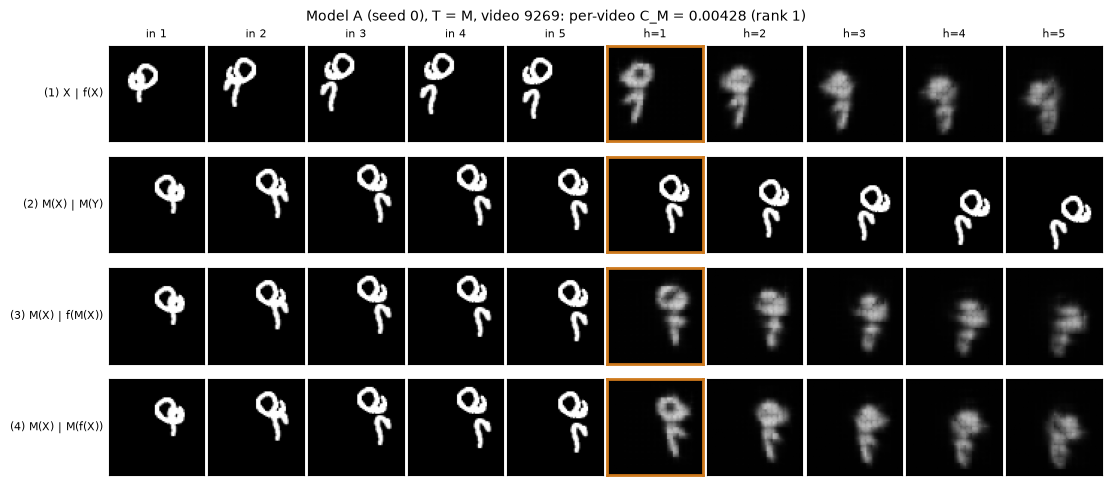

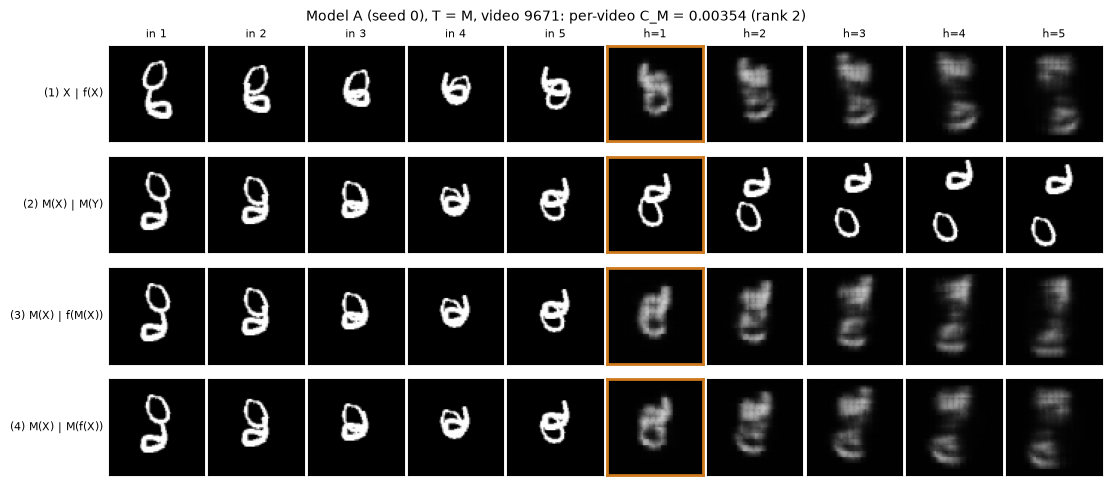

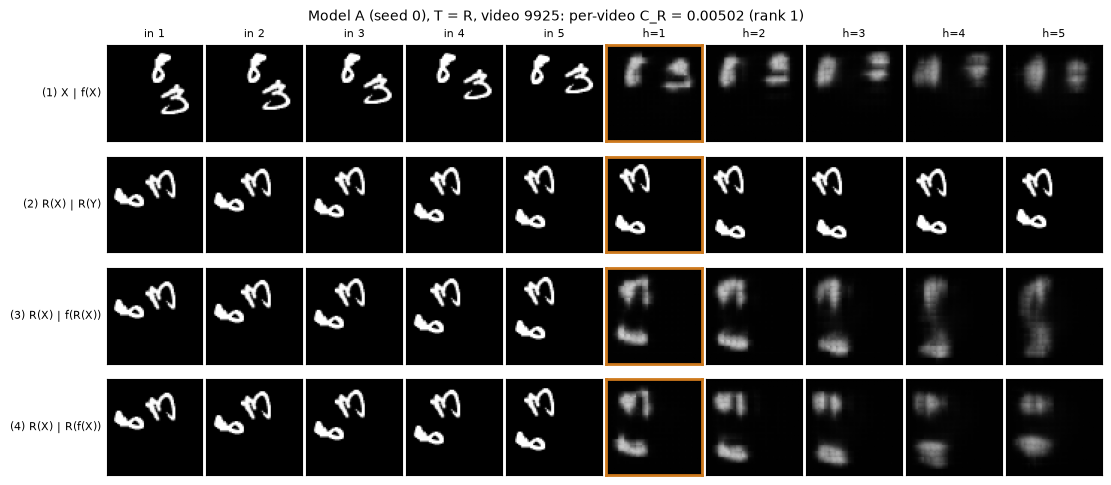

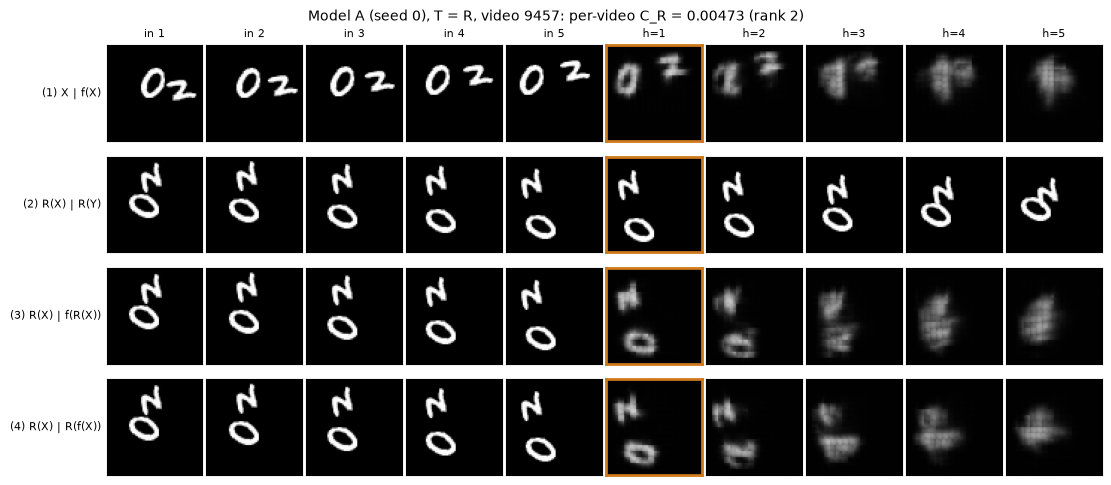

Figure 3 videos: {'M': [9269, 9671], 'R': [9925, 9457]}
GIFs: ['./q2_outputs/gifs/fig3_A_M_rank1_video9269.gif', './q2_outputs/gifs/fig3_A_M_rank2_video9671.gif', './q2_outputs/gifs/fig3_A_R_rank1_video9925.gif', './q2_outputs/gifs/fig3_A_R_rank2_video9457.gif']


In [15]:
# Figure 3 panels + animated GIFs (seed-0 model A)
from PIL import Image, ImageDraw
 
def to_np(img):
    return img.detach().float().cpu().numpy().squeeze()
 
def four_rows(f, i, T):
    """Returns the 4 rows x 10 frames of the Figure 3 panel for test video i (0-based in test split)."""
    X, Y, _ = make_windows(TEST_DEV[i:i + 1], 1, 1)
    X, Y = to_float(X), to_float(Y)
    with torch.no_grad():
        fX, fTX = f(X), f(T(X))
    TX, TY, TfX = T(X), T(Y), T(fX)
    rows = [torch.cat([X, fX], 1), torch.cat([TX, TY], 1), torch.cat([TX, fTX], 1), torch.cat([TX, TfX], 1)]
    return [[to_np(r[0, j]) for j in range(10)] for r in rows]
 
ROW_LABELS = {"M": ["(1) X | f(X)", "(2) M(X) | M(Y)", "(3) M(X) | f(M(X))", "(4) M(X) | M(f(X))"],
              "R": ["(1) X | f(X)", "(2) R(X) | R(Y)", "(3) R(X) | f(R(X))", "(4) R(X) | R(f(X))"]}
 
def save_panel(rows, labels, title, path):
    fig, axes = plt.subplots(4, 10, figsize=(11, 4.9))
    for r in range(4):
        for c in range(10):
            ax = axes[r, c]; ax.imshow(rows[r][c], cmap="gray", vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
            if c == 0: ax.set_ylabel(labels[r], rotation=0, ha="right", va="center", fontsize=8)
            if r == 0: ax.set_title(f"in {c+1}" if c < 5 else f"h={c-4}", fontsize=8)
            if c == 5:
                for s in ax.spines.values(): s.set_edgecolor("#ce791c"); s.set_linewidth(2)
    fig.suptitle(title, fontsize=10); fig.tight_layout(pad=0.3)
    fig.savefig(path, bbox_inches="tight", dpi=150); plt.show()
 
def save_gif(rows, labels, path, scale=2, gap=4, label_w=150):
    """One GIF frame per horizon h: each of the 4 rows shows its 5 input-side frames + the h-th future frame."""
    frames = []
    for h in range(5):
        H = 4 * (64 * scale + gap) + 18
        W = label_w + 6 * (64 * scale + gap) + gap
        canvas = Image.new("L", (W, H), 255); draw = ImageDraw.Draw(canvas)
        draw.text((label_w, 2), f"inputs 1-5 | forecast horizon h = {h+1}", fill=0)
        for r in range(4):
            y0 = 18 + r * (64 * scale + gap)
            draw.text((4, y0 + 28 * scale), labels[r], fill=0)
            for c, img in enumerate(rows[r][:5] + [rows[r][5 + h]]):
                tile = Image.fromarray((np.clip(img, 0, 1) * 255).astype(np.uint8)).resize((64 * scale, 64 * scale), Image.NEAREST)
                x0 = label_w + c * (64 * scale + gap) + (gap * 2 if c == 5 else 0)
                canvas.paste(tile, (x0, y0))
        frames.append(canvas)
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=800, loop=0)
 
mA0 = load_model("A", 0)
FIG3 = {"M": [int(i) for i in SYM["A"][0]["CM"].argsort(descending=True)[:2]],
        "R": [int(i) for i in SYM["A"][0]["CR"].argsort(descending=True)[:2]]}
json.dump(FIG3, open(f"{OUT}/results/fig3_videos.json", "w"))     # reused for Figure 6(a)
gif_paths = []
for T_name, T in (("M", M), ("R", R)):
    for rank, i in enumerate(FIG3[T_name], 1):
        rows = four_rows(mA0, i, T)
        c = float(SYM["A"][0]["C" + T_name][i])
        title = f"Model A (seed 0), T = {T_name}, video {9000+i}: per-video C_{T_name} = {fmt(c)} (rank {rank})"
        save_panel(rows, ROW_LABELS[T_name], title, f"{OUT}/figures/fig3_A_{T_name}_rank{rank}_video{9000+i}.pdf")
        gp = f"{OUT}/gifs/fig3_A_{T_name}_rank{rank}_video{9000+i}.gif"
        save_gif(rows, ROW_LABELS[T_name], gp); gif_paths.append(gp)
print("Figure 3 videos:", {k: [9000 + i for i in v] for k, v in FIG3.items()})
print("GIFs:", gif_paths)

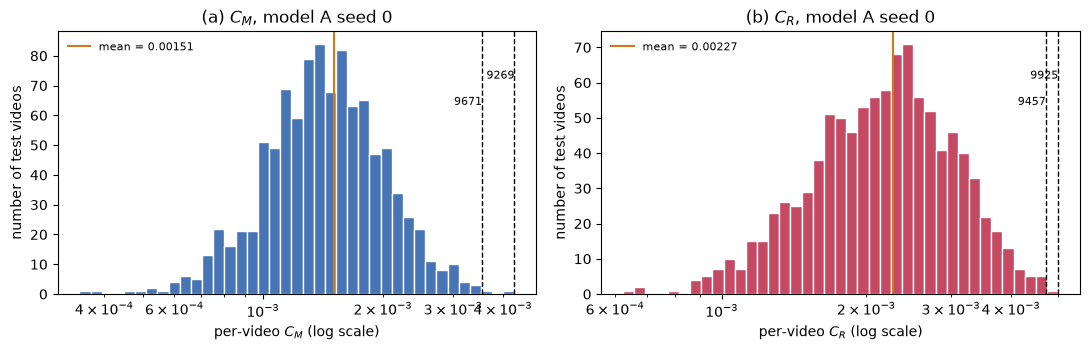

M median 0.00142 | 90th pct 0.00218 | max 0.00428
R median 0.00221 | 90th pct 0.00329 | max 0.00502


In [16]:
# Figure 4: histograms of per-video C_M and C_R (seed-0 model A)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, T_name, color in ((axes[0], "M", "#4774b5"), (axes[1], "R", "#c44963")):
    c = SYM["A"][0]["C" + T_name].numpy()
    bins = np.logspace(np.log10(max(c.min(), 1e-6)), np.log10(c.max()), 40)
    ax.hist(c, bins=bins, color=color, edgecolor="white")
    ax.set_xscale("log")
    for rank, i in enumerate(FIG3[T_name], 1):
        ax.axvline(c[i], color="k", ls="--", lw=1)
        ax.text(c[i], ax.get_ylim()[1] * (0.92 - 0.1 * rank), f" {9000+i}", fontsize=8, ha="right")
    ax.axvline(np.mean(c), color="#ce791c", lw=1.5, label=f"mean = {fmt(np.mean(c))}")
    ax.set(xlabel=f"per-video $C_{T_name}$ (log scale)", ylabel="number of test videos",
           title=f"({'a' if T_name == 'M' else 'b'}) $C_{T_name}$, model A seed 0")
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/figures/fig4_consistency_hist.pdf", bbox_inches="tight"); plt.show()
for T_name in ("M", "R"):
    c = SYM["A"][0]["C" + T_name].numpy()
    print(T_name, "median", fmt(np.median(c)), "| 90th pct", fmt(np.percentile(c, 90)), "| max", fmt(c.max()))

In [19]:
# Table 4: model A at faster speeds (t = 1)
def speed_eval(f):
    res = {}
    for k in (1, 2, 3):
        X, Y, valid = test_windows(k)
        mse = horizon_mse(predict(f, X), Y)                    # (N, 5)
        res[f"E2_{k}x"] = float(mse[:, :2].mean())
        res[f"MSEh_{k}x"] = mse[:, :int(valid[0].sum())].mean(0).tolist()
        if k <= 2:
            res[f"E5_{k}x"] = float(mse.mean())
    return res
 
SPEED = {name: {s: speed_eval(f) for s, f in predictors(name).items()} for name in ("A", "Copy-last", "Blank")}
json.dump({n: {str(s): v for s, v in d.items()} for n, d in SPEED.items()},
          open(f"{OUT}/results/table4.json", "w"), indent=1)
keys4 = ["E2_1x", "E2_2x", "E2_3x", "E5_1x", "E5_2x"]
table4 = [[n] + [summarize({s: v[k] for s, v in SPEED[n].items()}) for k in keys4] for n in ("A", "Copy-last", "Blank")]
for r in table4: print(r)
tex = latex_table(["Model", "$E^{(2)}$ 1$\\times$", "$E^{(2)}$ 2$\\times$", "$E^{(2)}$ 3$\\times$",
                   "$E^{(5)}$ 1$\\times$", "$E^{(5)}$ 2$\\times$"], table4,
                  "Model A at faster playback ($t=1$, test set). Learned models: mean (seed 0, seed 1). "
                  "Blank is included as an extra reference.", "tab:q2-4")
open(f"{OUT}/tables/table4.tex", "w").write(tex); print(tex)
for n in ("A", "Copy-last"):
    print(n, "per-horizon MSE (seed 0 / deterministic):", {k: [fmt(x) for x in v] for k, v in
          SPEED[n][0 if n == "A" else None].items() if k.startswith("MSEh")})

['A', '0.0187 (0.0192, 0.0182)', '0.0447 (0.0435, 0.0459)', '0.0528 (0.0516, 0.0540)', '0.0222 (0.0228, 0.0215)', '0.0489 (0.0469, 0.0508)']
['Copy-last', '0.0548', '0.0661', '0.0703', '0.0641', '0.0719']
['Blank', '0.0426', '0.0425', '0.0426', '0.0426', '0.0425']
\begin{table}[H]
\centering\small
\resizebox{\linewidth}{!}{%
\begin{tabular}{llllll}
\toprule
Model & $E^{(2)}$ 1$\times$ & $E^{(2)}$ 2$\times$ & $E^{(2)}$ 3$\times$ & $E^{(5)}$ 1$\times$ & $E^{(5)}$ 2$\times$ \\
\midrule
A & 0.0187 (0.0192, 0.0182) & 0.0447 (0.0435, 0.0459) & 0.0528 (0.0516, 0.0540) & 0.0222 (0.0228, 0.0215) & 0.0489 (0.0469, 0.0508) \\
Copy-last & 0.0548 & 0.0661 & 0.0703 & 0.0641 & 0.0719 \\
Blank & 0.0426 & 0.0425 & 0.0426 & 0.0426 & 0.0425 \\
\bottomrule
\end{tabular}}
\caption{Model A at faster playback ($t=1$, test set). Learned models: mean (seed 0, seed 1). Blank is included as an extra reference.}
\label{tab:q2-4}
\end{table}
A per-horizon MSE (seed 0 / deterministic): {'MSEh_1x': ['0.0174', '0.021

160 candidates; using test video 9021 (no overlap in inputs as well: True)


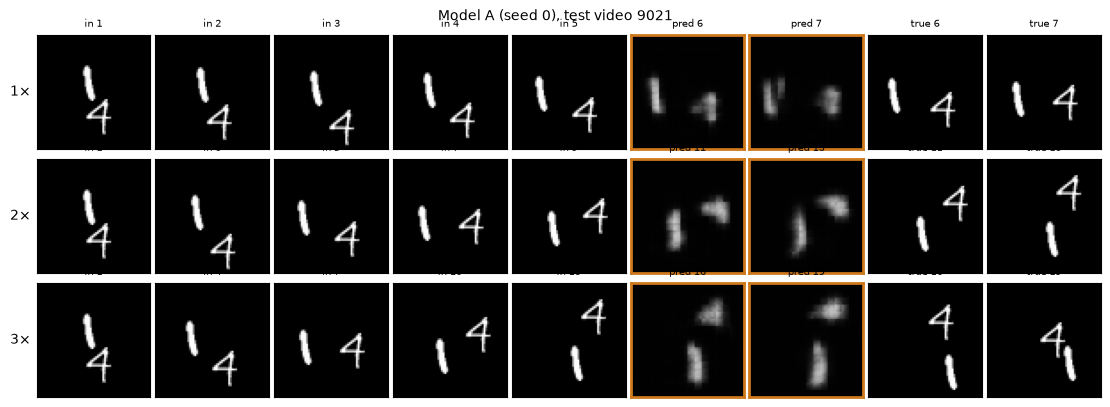

In [20]:
# Figure 5: one video at 1x, 2x, 3x (seed-0 model A)
SHOWN_TRUE = [6, 7, 11, 13, 16, 19]                           # first two targets at 1x, 2x, 3x
SHOWN_INPUTS = sorted({1, 2, 3, 4, 5, 7, 9, 10, 13})          # input frames at 1x, 2x, 3x
cands = [i for i in range(len(TEST_U8)) if not overlaps(TEST_U8[i], SHOWN_TRUE)]
strict = [i for i in cands if not overlaps(TEST_U8[i], SHOWN_INPUTS)]
FIG5 = (strict or cands)[0]
json.dump({"video": FIG5}, open(f"{OUT}/results/fig5_video.json", "w"))
print(f"{len(cands)} candidates; using test video {9000+FIG5} (no overlap in inputs as well: {FIG5 in strict})")
 
def speed_rows(f, i):
    rows = []
    for k in (1, 2, 3):
        X, Y, _ = make_windows(TEST_DEV[i:i + 1], 1, k)
        X, Y = to_float(X), to_float(Y)
        with torch.no_grad():
            P = f(X)
        rows.append([to_np(X[0, j]) for j in range(5)] + [to_np(P[0, j]) for j in range(2)] +
                    [to_np(Y[0, j]) for j in range(2)])
    return rows
 
def save_speed_figure(rows, title, path):
    fig, axes = plt.subplots(3, 9, figsize=(11, 4.0))
    frames = {1: ([1, 2, 3, 4, 5], [6, 7]), 2: ([1, 3, 5, 7, 9], [11, 13]), 3: ([1, 4, 7, 10, 13], [16, 19])}
    for r, k in enumerate((1, 2, 3)):
        fin, fout = frames[k]
        names = [f"in {f}" for f in fin] + [f"pred {f}" for f in fout] + [f"true {f}" for f in fout]
        for c in range(9):
            ax = axes[r, c]; ax.imshow(rows[r][c], cmap="gray", vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(names[c], fontsize=7)
            if c == 0: ax.set_ylabel(f"{k}×", rotation=0, ha="right", va="center", fontsize=10)
            if c in (5, 6):
                for s in ax.spines.values(): s.set_edgecolor("#ce791c"); s.set_linewidth(2)
    fig.suptitle(title, fontsize=10); fig.tight_layout(pad=0.3)
    fig.savefig(path, bbox_inches="tight", dpi=150); plt.show()
 
save_speed_figure(speed_rows(mA0, FIG5), f"Model A (seed 0), test video {9000+FIG5}",
                  f"{OUT}/figures/fig5_A_speeds_video{9000+FIG5}.pdf")

In [21]:
# Model D candidates: parameter budget and one-step reach
def reach_report(spec):
    """Longest one-step path (Q2.3 conventions): u_tau -> conv of every layer -> 1x1 output.
    Each layer's conv moves information dilation * (kernel // 2) cells; one cell = patch pixels."""
    per_layer = [d * (k // 2) for k, d in zip(spec["kernels"], spec["dilations"])]
    paths = {"u_tau / h^(1)_{tau-1}": sum(per_layer)}
    for l in range(1, len(per_layer)):
        paths[f"h^({l+1})_(tau-1)"] = sum(per_layer[l:])
    return spec["patch"] * sum(per_layer), per_layer, {k: v * spec["patch"] for k, v in paths.items()}
 
SPECS.update({
    "D_dil13": dict(patch=4, hidden=(64, 64), kernels=(3, 3), dilations=(1, 3)),   # layer 2 dilated by 3
    "D_patch8": dict(patch=8, hidden=(64, 64), kernels=(3, 3), dilations=(1, 1)),  # 8x8 folding
    "D_k5h40": dict(patch=4, hidden=(40, 40), kernels=(5, 5), dilations=(1, 1)),   # 5x5 kernels, 40 channels
})
BUDGET = int(1.5 * PARAMS_A)
for name in ("A", "D_dil13", "D_patch8", "D_k5h40"):
    p = n_params(ConvLSTMForecaster(**SPECS[name]))
    r, per_layer, paths = reach_report(SPECS[name])
    print(f"{name:9s} params {p:>8,} (<= {BUDGET:,}: {p <= BUDGET})  reach {r:>2} px  "
          f"cells per layer {per_layer}  paths {paths}")

A         params  480,784 (<= 721,176: True)  reach  8 px  cells per layer [1, 1]  paths {'u_tau / h^(1)_{tau-1}': 8, 'h^(2)_(tau-1)': 4}
D_dil13   params  480,784 (<= 721,176: True)  reach 16 px  cells per layer [1, 3]  paths {'u_tau / h^(1)_{tau-1}': 16, 'h^(2)_(tau-1)': 12}
D_patch8  params  594,496 (<= 721,176: True)  reach 16 px  cells per layer [1, 1]  paths {'u_tau / h^(1)_{tau-1}': 16, 'h^(2)_(tau-1)': 8}
D_k5h40   params  544,976 (<= 721,176: True)  reach 16 px  cells per layer [2, 2]  paths {'u_tau / h^(1)_{tau-1}': 16, 'h^(2)_(tau-1)': 8}


In [22]:
# Choose model D on VALIDATION split (seed 0, speed-augmented, full 30-epoch protocol)
@torch.no_grad()
def val_eval(model, bs=100):
    model.eval(); res = {}
    for k in (1, 2, 3):
        tot2, tot5 = 0.0, 0.0
        for s in range(0, len(VAL_DEV), bs):
            X, Y, _ = make_windows(VAL_DEV[s:s + bs], 1, k)
            mse = horizon_mse(model(to_float(X)), to_float(Y))
            tot2 += mse[:, :2].mean(1).sum().item(); tot5 += mse.mean(1).sum().item()
        res[f"E2_{k}x"] = tot2 / len(VAL_DEV)
        if k == 1: res["E5_1x"] = tot5 / len(VAL_DEV)
    return res
 
CANDIDATES = ("D_dil13", "D_patch8", "D_k5h40")
VALRES = {}
for name in CANDIDATES:
    VALRES[name] = val_eval(train_model(name, SPECS[name], seed=0, speed_aug=True, sym_aug=False))
    print(name, {k: fmt(v) for k, v in VALRES[name].items()})
# Selection rule (fixed in advance): lowest mean validation E2 over 1x, 2x, 3x.
score = {n: np.mean([VALRES[n][f"E2_{k}x"] for k in (1, 2, 3)]) for n in CANDIDATES}
D_CHOICE = min(score, key=score.get)
print("validation mean E2:", {n: fmt(v) for n, v in score.items()}, "-> chosen:", D_CHOICE)
json.dump({"val": VALRES, "score": score, "choice": D_CHOICE}, open(f"{OUT}/results/d_selection.json", "w"), indent=1)

D_dil13 s0 ep  1  train 0.04644  val E5 0.03892  14.0s
D_dil13 s0 ep  2  train 0.03935  val E5 0.03840  13.3s
D_dil13 s0 ep  3  train 0.03889  val E5 0.03802  13.7s
D_dil13 s0 ep  4  train 0.03857  val E5 0.03778  14.0s
D_dil13 s0 ep  5  train 0.03832  val E5 0.03736  14.2s
D_dil13 s0 ep  6  train 0.03750  val E5 0.03633  14.2s
D_dil13 s0 ep  7  train 0.03690  val E5 0.03536  14.5s
D_dil13 s0 ep  8  train 0.03643  val E5 0.03479  14.5s
D_dil13 s0 ep  9  train 0.03605  val E5 0.03501  14.2s
D_dil13 s0 ep 10  train 0.03593  val E5 0.03431  14.2s
D_dil13 s0 ep 11  train 0.03554  val E5 0.03427  14.4s
D_dil13 s0 ep 12  train 0.03526  val E5 0.03326  14.3s
D_dil13 s0 ep 13  train 0.03497  val E5 0.03275  14.6s
D_dil13 s0 ep 14  train 0.03458  val E5 0.03287  14.5s
D_dil13 s0 ep 15  train 0.03424  val E5 0.03261  14.8s
D_dil13 s0 ep 16  train 0.03412  val E5 0.03173  14.7s
D_dil13 s0 ep 17  train 0.03369  val E5 0.03169  15.8s
D_dil13 s0 ep 18  train 0.03354  val E5 0.03137  16.3s
D_dil13 s0

In [23]:
# Train models B, C, D (seeds 0 and 1)
import shutil
SPECS["B"] = SPECS["A"]; SPECS["C"] = SPECS["A"]; SPECS["D"] = SPECS[D_CHOICE]
# The chosen candidate's seed-0 run was trained with exactly model D's protocol: reuse it.
if not os.path.exists(ckpt_path("D", 0)):
    shutil.copy(ckpt_path(D_CHOICE, 0), ckpt_path("D", 0))
for seed in (0, 1):
    train_model("B", SPECS["B"], seed, speed_aug=False, sym_aug=True)
    train_model("C", SPECS["C"], seed, speed_aug=True, sym_aug=False)
    train_model("D", SPECS["D"], seed, speed_aug=True, sym_aug=False)

B s0 ep  1  train 0.04610  val E5 0.03932  11.1s
B s0 ep  2  train 0.03969  val E5 0.03856  10.7s
B s0 ep  3  train 0.03865  val E5 0.03732  10.7s
B s0 ep  4  train 0.03716  val E5 0.03581  10.7s
B s0 ep  5  train 0.03527  val E5 0.03376  10.8s
B s0 ep  6  train 0.03363  val E5 0.03229  10.9s
B s0 ep  7  train 0.03241  val E5 0.03134  11.0s
B s0 ep  8  train 0.03147  val E5 0.03043  11.0s
B s0 ep  9  train 0.03062  val E5 0.03027  11.1s
B s0 ep 10  train 0.03007  val E5 0.02948  11.1s
B s0 ep 11  train 0.02948  val E5 0.02899  11.1s
B s0 ep 12  train 0.02908  val E5 0.02878  11.1s
B s0 ep 13  train 0.02880  val E5 0.02830  11.2s
B s0 ep 14  train 0.02830  val E5 0.02774  11.2s
B s0 ep 15  train 0.02787  val E5 0.02740  11.2s
B s0 ep 16  train 0.02751  val E5 0.02704  11.2s
B s0 ep 17  train 0.02721  val E5 0.02698  11.2s
B s0 ep 18  train 0.02676  val E5 0.02642  11.2s
B s0 ep 19  train 0.02653  val E5 0.02618  11.2s
B s0 ep 20  train 0.02608  val E5 0.02572  11.2s
B s0 ep 21  train 0.

In [24]:
# Table 5: models A-D on the test split
@torch.no_grad()
def inference_time(f, X, bs=32):
    """Wall-clock time to predict all test videos (1x, t=1) at batch size 32; data already on device."""
    if isinstance(f, nn.Module): f.eval()
    f(X[:bs]); sync()                                            # warm-up (cuDNN autotuning), not timed
    t0 = time.perf_counter()
    for s in range(0, len(X), bs):
        f(X[s:s + bs])
    sync()
    return time.perf_counter() - t0
 
def full_eval(name):
    """Per seed: E5, C_M, E_M, C_R, E_R (1x), E2 at 1x/2x/3x, inference time; plus train time/epoch."""
    out = {}
    for seed, f in predictors(name).items():
        sym, _ = symmetry_eval(f, X1, Y1)
        r = {k: float(v.mean()) for k, v in sym.items()}
        sp = speed_eval(f)
        r.update({k: sp[k] for k in ("E2_1x", "E2_2x", "E2_3x")})
        r["infer_s"] = inference_time(f, X1)
        r["train_s"] = train_time_per_epoch(name, seed) if seed is not None else 0.0
        out[seed] = r
    return out
 
RES5 = {name: full_eval(name) for name in ("A", "B", "C", "D")}
json.dump({n: {str(s): v for s, v in d.items()} for n, d in RES5.items()},
          open(f"{OUT}/results/table5.json", "w"), indent=1)
 
ROWS5 = [("$E^{(5)}$ 1$\\times$", "E5"), ("$C_M$", "CM"), ("$E_M$", "EM"), ("$C_R$", "CR"), ("$E_R$", "ER"),
         ("$E^{(2)}$ 1$\\times$", "E2_1x"), ("$E^{(2)}$ 2$\\times$", "E2_2x"), ("$E^{(2)}$ 3$\\times$", "E2_3x"),
         ("Train time / epoch (s)", "train_s"), ("Inference time, 1000 videos (s)", "infer_s")]
 
def transposed_table(results, models, rows, params, caption, label):
    body = []
    for label_, key in rows:
        body.append([label_] + [summarize({s: v[key] for s, v in results[m].items()}) for m in models])
    body.append(["Trainable parameters"] + [f"{params[m]:,}" for m in models])
    return latex_table(["Metric"] + [f"Model {m}" if len(m) == 1 else m for m in models], body, caption, label), body
 
PARAMS = {m: n_params(ConvLSTMForecaster(**SPECS[m])) for m in ("A", "B", "C", "D")}
tex, body = transposed_table(RES5, ["A", "B", "C", "D"], ROWS5, PARAMS,
    "Models A--D on the test split ($t=1$). Entries: mean (seed 0, seed 1). "
    f"Hardware: {torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'}. "
    "Training time: mean wall-clock per epoch over 30 epochs; inference: all 1{,}000 test videos "
    "at batch size 32.", "tab:q2-5")
for r in body: print(r)
open(f"{OUT}/tables/table5.tex", "w").write(tex); print(tex)

['$E^{(5)}$ 1$\\times$', '0.0222 (0.0228, 0.0215)', '0.0226 (0.0232, 0.0220)', '0.0266 (0.0271, 0.0260)', '0.0333 (0.0280, 0.0386)']
['$C_M$', '0.00168 (0.00151, 0.00186)', '0.00122 (0.00123, 0.00121)', '0.00130 (0.00108, 0.00151)', '9.52e-04 (0.00190, 1.12e-06)']
['$E_M$', '0.0228 (0.0234, 0.0223)', '0.0226 (0.0232, 0.0220)', '0.0268 (0.0274, 0.0262)', '0.0334 (0.0281, 0.0386)']
['$C_R$', '0.00272 (0.00227, 0.00318)', '0.00147 (0.00153, 0.00141)', '0.00254 (0.00191, 0.00317)', '0.00140 (0.00279, 7.75e-07)']
['$E_R$', '0.0238 (0.0242, 0.0234)', '0.0225 (0.0230, 0.0220)', '0.0277 (0.0281, 0.0274)', '0.0337 (0.0289, 0.0386)']
['$E^{(2)}$ 1$\\times$', '0.0187 (0.0192, 0.0182)', '0.0189 (0.0194, 0.0184)', '0.0229 (0.0235, 0.0224)', '0.0320 (0.0254, 0.0386)']
['$E^{(2)}$ 2$\\times$', '0.0447 (0.0435, 0.0459)', '0.0443 (0.0447, 0.0438)', '0.0288 (0.0292, 0.0284)', '0.0333 (0.0280, 0.0385)']
['$E^{(2)}$ 3$\\times$', '0.0528 (0.0516, 0.0540)', '0.0495 (0.0510, 0.0481)', '0.0333 (0.0335, 0.0331

In [25]:
# Handling the optimaztion failure: Replace the model classes (backward compatible: A, B, C, D_k5h40 checkpoints still load)
# Adds an optional per-gate GroupNorm for model D only. Models A-C keep norm=False (no normalisation)
class ConvLSTMCell(nn.Module):
    def __init__(self, cin, hidden, kernel=3, dilation=1, norm=False):
        super().__init__()
        self.hidden = hidden
        pad = dilation * (kernel // 2)
        self.conv = nn.Conv2d(cin + hidden, 4 * hidden, kernel, stride=1, padding=pad,
                              dilation=dilation, bias=True)
        # 4 groups = one group per gate (channels are ordered [i, f, o, g]); keeps gate
        # pre-activations at unit scale so the sigmoid gates cannot saturate shut.
        self.norm = nn.GroupNorm(4, 4 * hidden) if norm else nn.Identity()
 
    def forward(self, u, state):
        h, c = state
        i, f, o, g = self.norm(self.conv(torch.cat([u, h], dim=1))).chunk(4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c
 
 
class ConvLSTMForecaster(nn.Module):
    def __init__(self, patch=4, hidden=(64, 64), kernels=(3, 3), dilations=(1, 1), norm=False):
        super().__init__()
        self.patch, self.hidden = patch, tuple(hidden)
        cells, cin = [], patch * patch
        for h, k, d in zip(hidden, kernels, dilations):
            cells.append(ConvLSTMCell(cin, h, k, d, norm)); cin = h
        self.cells = nn.ModuleList(cells)
        self.out = nn.Conv2d(hidden[-1], patch * patch, 1, bias=True)
 
    def step(self, frame, states):
        u = F.pixel_unshuffle(frame, self.patch)
        new = []
        for cell, st in zip(self.cells, states):
            h, c = cell(u, st)
            new.append((h, c)); u = h
        return torch.sigmoid(F.pixel_shuffle(self.out(u), self.patch)), new
 
    def forward(self, X):
        B, _, _, H, W = X.shape
        s = H // self.patch
        states = [(X.new_zeros(B, h, s, s), X.new_zeros(B, h, s, s)) for h in self.hidden]
        preds, pred = [], None
        for tau in range(1, 10):
            u = X[:, tau - 1] if tau <= 5 else pred
            pred, states = self.step(u, states)
            if tau >= 5:
                preds.append(pred)
        return torch.stack(preds, dim=1)
 
assert n_params(ConvLSTMForecaster(**SPECS["A"])) == 480_784          # A unchanged
SPECS["D_k5h40gn"] = dict(SPECS["D_k5h40"], norm=True)
print("D_k5h40gn params:", n_params(ConvLSTMForecaster(**SPECS["D_k5h40gn"])), "| reach:",
      reach_report(SPECS["D_k5h40gn"])[0], "px  (GroupNorm is pointwise in space: reach unchanged)")

D_k5h40gn params: 545616 | reach: 16 px  (GroupNorm is pointwise in space: reach unchanged)


In [26]:
# Keep failed run under its candidate name, then train GroupNorm variant (seeds 0, 1)
import shutil
for s in (0, 1):
    src, dst = ckpt_path("D", s), ckpt_path("D_k5h40", s)
    if os.path.exists(src) and not os.path.exists(dst):   # seed 0 already exists (it was the source)
        shutil.copy(src, dst)
 
for s in (0, 1):
    train_model("D_k5h40gn", SPECS["D_k5h40gn"], s, speed_aug=True, sym_aug=False)

D_k5h40gn s0 ep  1  train 0.05926  val E5 0.03353  9.8s
D_k5h40gn s0 ep  2  train 0.03261  val E5 0.02934  9.7s
D_k5h40gn s0 ep  3  train 0.03064  val E5 0.02759  9.7s
D_k5h40gn s0 ep  4  train 0.02949  val E5 0.02688  9.9s
D_k5h40gn s0 ep  5  train 0.02876  val E5 0.02619  9.9s
D_k5h40gn s0 ep  6  train 0.02797  val E5 0.02525  9.9s
D_k5h40gn s0 ep  7  train 0.02734  val E5 0.02447  9.9s
D_k5h40gn s0 ep  8  train 0.02685  val E5 0.02388  10.0s
D_k5h40gn s0 ep  9  train 0.02626  val E5 0.02360  10.2s
D_k5h40gn s0 ep 10  train 0.02601  val E5 0.02283  10.0s
D_k5h40gn s0 ep 11  train 0.02554  val E5 0.02263  10.2s
D_k5h40gn s0 ep 12  train 0.02534  val E5 0.02225  10.2s
D_k5h40gn s0 ep 13  train 0.02492  val E5 0.02177  10.3s
D_k5h40gn s0 ep 14  train 0.02465  val E5 0.02157  10.5s
D_k5h40gn s0 ep 15  train 0.02440  val E5 0.02148  10.4s
D_k5h40gn s0 ep 16  train 0.02420  val E5 0.02114  10.5s
D_k5h40gn s0 ep 17  train 0.02393  val E5 0.02068  10.5s
D_k5h40gn s0 ep 18  train 0.02375  val

In [27]:
# Choose D between the two designs on the VALIDATION split, using BOTH required seeds
VAL2 = {}
for name in ("D_k5h40", "D_k5h40gn"):
    VAL2[name] = {s: val_eval(load_model(name, s)) for s in (0, 1)}
    for s in (0, 1):
        print(name, "seed", s, {k: fmt(v) for k, v in VAL2[name][s].items()})
# Rule (stated before looking): lowest validation E2 averaged over 1x/2x/3x AND over seeds 0 and 1.
score2 = {n: np.mean([VAL2[n][s][f"E2_{k}x"] for s in (0, 1) for k in (1, 2, 3)]) for n in VAL2}
D_CHOICE = min(score2, key=score2.get)
print("seed-averaged validation E2:", {n: fmt(v) for n, v in score2.items()}, "-> D =", D_CHOICE)
for name in VAL2:
    log1 = torch.load(ckpt_path(name, 1), map_location="cpu")["log"]["val_E5"]
    print(name, "seed 1: epochs with val E5 >= 0.0394 (blank-level plateau):", sum(v >= 0.0394 for v in log1))
json.dump({"val": {n: {str(s): v for s, v in d.items()} for n, d in VAL2.items()}, "score": score2,
           "choice": D_CHOICE}, open(f"{OUT}/results/d_selection_round2.json", "w"), indent=1)
 
# Install the chosen design as model D (both seeds) and refresh the spec used by load/eval.
SPECS["D"] = SPECS[D_CHOICE]
for s in (0, 1):
    shutil.copy(ckpt_path(D_CHOICE, s), ckpt_path("D", s))
print("Model D is now", D_CHOICE, SPECS["D"])

D_k5h40 seed 0 {'E2_1x': '0.0251', 'E5_1x': '0.0277', 'E2_2x': '0.0279', 'E2_3x': '0.0305'}
D_k5h40 seed 1 {'E2_1x': '0.0380', 'E5_1x': '0.0379', 'E2_2x': '0.0379', 'E2_3x': '0.0379'}
D_k5h40gn seed 0 {'E2_1x': '0.0154', 'E5_1x': '0.0192', 'E2_2x': '0.0206', 'E2_3x': '0.0253'}
D_k5h40gn seed 1 {'E2_1x': '0.0150', 'E5_1x': '0.0184', 'E2_2x': '0.0208', 'E2_3x': '0.0251'}
seed-averaged validation E2: {'D_k5h40': '0.0329', 'D_k5h40gn': '0.0204'} -> D = D_k5h40gn
D_k5h40 seed 1: epochs with val E5 >= 0.0394 (blank-level plateau): 16
D_k5h40gn seed 1: epochs with val E5 >= 0.0394 (blank-level plateau): 0
Model D is now D_k5h40gn {'patch': 4, 'hidden': (40, 40), 'kernels': (5, 5), 'dilations': (1, 1), 'norm': True}


In [28]:
# Model C + the same GroupNorm: separates "reach" from "normalisation"
SPECS["C_gn"] = dict(SPECS["A"], norm=True)
for s in (0, 1):
    train_model("C_gn", SPECS["C_gn"], s, speed_aug=True, sym_aug=False)

C_gn s0 ep  1  train 0.04860  val E5 0.03238  10.7s
C_gn s0 ep  2  train 0.03299  val E5 0.02946  10.7s
C_gn s0 ep  3  train 0.03168  val E5 0.02835  10.7s
C_gn s0 ep  4  train 0.03080  val E5 0.02730  10.7s
C_gn s0 ep  5  train 0.03025  val E5 0.02663  10.7s
C_gn s0 ep  6  train 0.02962  val E5 0.02567  10.7s
C_gn s0 ep  7  train 0.02908  val E5 0.02468  10.7s
C_gn s0 ep  8  train 0.02859  val E5 0.02425  10.8s
C_gn s0 ep  9  train 0.02821  val E5 0.02391  10.8s
C_gn s0 ep 10  train 0.02796  val E5 0.02318  10.8s
C_gn s0 ep 11  train 0.02757  val E5 0.02290  10.9s
C_gn s0 ep 12  train 0.02739  val E5 0.02240  10.9s
C_gn s0 ep 13  train 0.02710  val E5 0.02233  11.0s
C_gn s0 ep 14  train 0.02683  val E5 0.02178  11.0s
C_gn s0 ep 15  train 0.02662  val E5 0.02146  11.0s
C_gn s0 ep 16  train 0.02641  val E5 0.02120  11.1s
C_gn s0 ep 17  train 0.02621  val E5 0.02090  11.1s
C_gn s0 ep 18  train 0.02606  val E5 0.02109  11.1s
C_gn s0 ep 19  train 0.02584  val E5 0.02069  11.1s
C_gn s0 ep 2

In [29]:
# RERUNNING => Table 5: models A-D on the test split
@torch.no_grad()
def inference_time(f, X, bs=32):
    """Wall-clock time to predict all test videos (1x, t=1) at batch size 32; data already on device."""
    if isinstance(f, nn.Module): f.eval()
    f(X[:bs]); sync()                                            # warm-up (cuDNN autotuning), not timed
    t0 = time.perf_counter()
    for s in range(0, len(X), bs):
        f(X[s:s + bs])
    sync()
    return time.perf_counter() - t0
 
def full_eval(name):
    """Per seed: E5, C_M, E_M, C_R, E_R (1x), E2 at 1x/2x/3x, inference time; plus train time/epoch."""
    out = {}
    for seed, f in predictors(name).items():
        sym, _ = symmetry_eval(f, X1, Y1)
        r = {k: float(v.mean()) for k, v in sym.items()}
        sp = speed_eval(f)
        r.update({k: sp[k] for k in ("E2_1x", "E2_2x", "E2_3x")})
        r["infer_s"] = inference_time(f, X1)
        r["train_s"] = train_time_per_epoch(name, seed) if seed is not None else 0.0
        out[seed] = r
    return out
 
RES5 = {name: full_eval(name) for name in ("A", "B", "C", "D")}
json.dump({n: {str(s): v for s, v in d.items()} for n, d in RES5.items()},
          open(f"{OUT}/results/table5.json", "w"), indent=1)
 
ROWS5 = [("$E^{(5)}$ 1$\\times$", "E5"), ("$C_M$", "CM"), ("$E_M$", "EM"), ("$C_R$", "CR"), ("$E_R$", "ER"),
         ("$E^{(2)}$ 1$\\times$", "E2_1x"), ("$E^{(2)}$ 2$\\times$", "E2_2x"), ("$E^{(2)}$ 3$\\times$", "E2_3x"),
         ("Train time / epoch (s)", "train_s"), ("Inference time, 1000 videos (s)", "infer_s")]
 
def transposed_table(results, models, rows, params, caption, label):
    body = []
    for label_, key in rows:
        body.append([label_] + [summarize({s: v[key] for s, v in results[m].items()}) for m in models])
    body.append(["Trainable parameters"] + [f"{params[m]:,}" for m in models])
    return latex_table(["Metric"] + [f"Model {m}" if len(m) == 1 else m for m in models], body, caption, label), body
 
PARAMS = {m: n_params(ConvLSTMForecaster(**SPECS[m])) for m in ("A", "B", "C", "D")}
tex, body = transposed_table(RES5, ["A", "B", "C", "D"], ROWS5, PARAMS,
    "Models A--D on the test split ($t=1$). Entries: mean (seed 0, seed 1). "
    f"Hardware: {torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'}. "
    "Training time: mean wall-clock per epoch over 30 epochs; inference: all 1{,}000 test videos "
    "at batch size 32.", "tab:q2-5")
for r in body: print(r)
open(f"{OUT}/tables/table5.tex", "w").write(tex); print(tex)

['$E^{(5)}$ 1$\\times$', '0.0222 (0.0228, 0.0215)', '0.0226 (0.0232, 0.0220)', '0.0266 (0.0271, 0.0260)', '0.0190 (0.0193, 0.0187)']
['$C_M$', '0.00168 (0.00151, 0.00186)', '0.00122 (0.00123, 0.00121)', '0.00130 (0.00108, 0.00151)', '0.00334 (0.00356, 0.00313)']
['$E_M$', '0.0228 (0.0234, 0.0223)', '0.0226 (0.0232, 0.0220)', '0.0268 (0.0274, 0.0262)', '0.0201 (0.0203, 0.0199)']
['$C_R$', '0.00272 (0.00227, 0.00318)', '0.00147 (0.00153, 0.00141)', '0.00254 (0.00191, 0.00317)', '0.00473 (0.00505, 0.00442)']
['$E_R$', '0.0238 (0.0242, 0.0234)', '0.0225 (0.0230, 0.0220)', '0.0277 (0.0281, 0.0274)', '0.0215 (0.0218, 0.0212)']
['$E^{(2)}$ 1$\\times$', '0.0187 (0.0192, 0.0182)', '0.0189 (0.0194, 0.0184)', '0.0229 (0.0235, 0.0224)', '0.0154 (0.0156, 0.0153)']
['$E^{(2)}$ 2$\\times$', '0.0447 (0.0435, 0.0459)', '0.0443 (0.0447, 0.0438)', '0.0288 (0.0292, 0.0284)', '0.0206 (0.0205, 0.0207)']
['$E^{(2)}$ 3$\\times$', '0.0528 (0.0516, 0.0540)', '0.0495 (0.0510, 0.0481)', '0.0333 (0.0335, 0.0331)',

In [30]:
# Control row (report under Table 5 as an extra line)
RES5["C_gn"] = full_eval("C_gn")
for label_, key in ROWS5:
    print(f"{label_:<35}", summarize({s: v[key] for s, v in RES5["C_gn"].items()}))
json.dump({str(s): v for s, v in RES5["C_gn"].items()}, open(f"{OUT}/results/table5_control_C_gn.json", "w"), indent=1)

$E^{(5)}$ 1$\times$                 0.0194 (0.0200, 0.0188)
$C_M$                               0.00323 (0.00325, 0.00320)
$E_M$                               0.0204 (0.0209, 0.0199)
$C_R$                               0.00534 (0.00609, 0.00459)
$E_R$                               0.0219 (0.0225, 0.0213)
$E^{(2)}$ 1$\times$                 0.0154 (0.0157, 0.0150)
$E^{(2)}$ 2$\times$                 0.0234 (0.0236, 0.0233)
$E^{(2)}$ 3$\times$                 0.0302 (0.0301, 0.0303)
Train time / epoch (s)              11.2 (11.0, 11.4)
Inference time, 1000 videos (s)     0.448 (0.446, 0.449)


In [31]:
# Re-write Table 5 with the control model as an extra column
PARAMS["C_gn"] = n_params(ConvLSTMForecaster(**SPECS["C_gn"]))
tex, body = transposed_table(RES5, ["A", "B", "C", "D", "C_gn"], ROWS5, PARAMS,
    "Models A--D on the test split ($t=1$), plus a control (C+GN: model C's architecture with "
    "model D's per-gate GroupNorm, trained like C). Entries: mean (seed 0, seed 1). "
    f"Hardware: {torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'}. "
    "Training time: mean wall-clock per epoch over 30 epochs; inference: all 1{,}000 test videos "
    "at batch size 32.", "tab:q2-5")
tex = tex.replace("& C_gn \\\\", "& C+GN (control) \\\\")
open(f"{OUT}/tables/table5.tex", "w").write(tex); print(tex)

\begin{table}[H]
\centering\small
\resizebox{\linewidth}{!}{%
\begin{tabular}{llllll}
\toprule
Metric & Model A & Model B & Model C & Model D & C+GN (control) \\
\midrule
$E^{(5)}$ 1$\times$ & 0.0222 (0.0228, 0.0215) & 0.0226 (0.0232, 0.0220) & 0.0266 (0.0271, 0.0260) & 0.0190 (0.0193, 0.0187) & 0.0194 (0.0200, 0.0188) \\
$C_M$ & 0.00168 (0.00151, 0.00186) & 0.00122 (0.00123, 0.00121) & 0.00130 (0.00108, 0.00151) & 0.00334 (0.00356, 0.00313) & 0.00323 (0.00325, 0.00320) \\
$E_M$ & 0.0228 (0.0234, 0.0223) & 0.0226 (0.0232, 0.0220) & 0.0268 (0.0274, 0.0262) & 0.0201 (0.0203, 0.0199) & 0.0204 (0.0209, 0.0199) \\
$C_R$ & 0.00272 (0.00227, 0.00318) & 0.00147 (0.00153, 0.00141) & 0.00254 (0.00191, 0.00317) & 0.00473 (0.00505, 0.00442) & 0.00534 (0.00609, 0.00459) \\
$E_R$ & 0.0238 (0.0242, 0.0234) & 0.0225 (0.0230, 0.0220) & 0.0277 (0.0281, 0.0274) & 0.0215 (0.0218, 0.0212) & 0.0219 (0.0225, 0.0213) \\
$E^{(2)}$ 1$\times$ & 0.0187 (0.0192, 0.0182) & 0.0189 (0.0194, 0.0184) & 0.0229 (0.0235, 

In [32]:
# Train D+B: model D's architecture with speed AND symmetry augmentation (seeds 0, 1)
SPECS["DB"] = SPECS["D"]
for s in (0, 1):
    train_model("DB", SPECS["DB"], s, speed_aug=True, sym_aug=True)

DB s0 ep  1  train 0.05923  val E5 0.03359  11.3s
DB s0 ep  2  train 0.03261  val E5 0.02939  11.0s
DB s0 ep  3  train 0.03062  val E5 0.02781  11.1s
DB s0 ep  4  train 0.02964  val E5 0.02681  11.2s
DB s0 ep  5  train 0.02900  val E5 0.02660  11.1s
DB s0 ep  6  train 0.02843  val E5 0.02587  11.0s
DB s0 ep  7  train 0.02786  val E5 0.02537  11.2s
DB s0 ep  8  train 0.02747  val E5 0.02459  11.2s
DB s0 ep  9  train 0.02700  val E5 0.02439  11.2s
DB s0 ep 10  train 0.02670  val E5 0.02405  11.3s
DB s0 ep 11  train 0.02625  val E5 0.02376  11.4s
DB s0 ep 12  train 0.02596  val E5 0.02300  11.5s
DB s0 ep 13  train 0.02572  val E5 0.02308  11.5s
DB s0 ep 14  train 0.02540  val E5 0.02274  11.6s
DB s0 ep 15  train 0.02504  val E5 0.02225  11.6s
DB s0 ep 16  train 0.02488  val E5 0.02186  11.7s
DB s0 ep 17  train 0.02468  val E5 0.02178  11.7s
DB s0 ep 18  train 0.02449  val E5 0.02178  11.7s
DB s0 ep 19  train 0.02429  val E5 0.02172  11.8s
DB s0 ep 20  train 0.02413  val E5 0.02095  11.8s


In [33]:
# Symmetrised forecaster  f_bar(X) = 1/8 sum_g g^{-1}( f(g(X)) )
class Symmetrised(nn.Module):
    def __init__(self, base):
        super().__init__()
        self.base = base.eval()
 
    @torch.no_grad()
    def forward(self, X):
        B = X.shape[0]
        P = self.base(torch.cat([apply_g(X, g) for g in G], dim=0))       # all 8 transforms in one pass
        return sum(invert_g(P[i * B:(i + 1) * B], g) for i, g in enumerate(G)) / len(G)
 
def sym_predictors(name):
    return {s: Symmetrised(load_model(name, s)) for s in (0, 1)}
 
# Sanity check on a few test videos: consistency must vanish up to floating-point error
fb = Symmetrised(load_model("D", 0))
Xs = X1[:8]
for T_name, T in (("M", M), ("R", R)):
    print(T_name, "max |f_bar(T X) - T f_bar(X)| =", (fb(T(Xs)) - T(fb(Xs))).abs().max().item())

M max |f_bar(T X) - T f_bar(X)| = 1.1920928955078125e-07
R max |f_bar(T X) - T f_bar(X)| = 1.7881393432617188e-07


In [34]:
# Final-model choice on the VALIDATION split: symmetrised D vs symmetrised D+B
@torch.no_grad()
def val_eval_f(f, bs=100):
    res = {}
    for k in (1, 2, 3):
        tot2, tot5 = 0.0, 0.0
        for s in range(0, len(VAL_DEV), bs):
            X, Y, _ = make_windows(VAL_DEV[s:s + bs], 1, k)
            mse = horizon_mse(f(to_float(X)), to_float(Y))
            tot2 += mse[:, :2].mean(1).sum().item(); tot5 += mse.mean(1).sum().item()
        res[f"E2_{k}x"] = tot2 / len(VAL_DEV)
        if k == 1: res["E5_1x"] = tot5 / len(VAL_DEV)
    return res
 
VAL3 = {n: {s: val_eval_f(f) for s, f in sym_predictors(n).items()} for n in ("D", "DB")}
for n in VAL3:
    for s in (0, 1): print("sym", n, "seed", s, {k: fmt(v) for k, v in VAL3[n][s].items()})
# Rule (same as for model D): lowest validation E2 averaged over 1x/2x/3x and both seeds.
score3 = {n: np.mean([VAL3[n][s][f"E2_{k}x"] for s in (0, 1) for k in (1, 2, 3)]) for n in VAL3}
FINAL = min(score3, key=score3.get)
print("validation score:", {n: fmt(v) for n, v in score3.items()}, "-> final model = symmetrised", FINAL)
json.dump({"val": {n: {str(s): v for s, v in d.items()} for n, d in VAL3.items()}, "score": score3,
           "final": FINAL}, open(f"{OUT}/results/final_selection.json", "w"), indent=1)

sym D seed 0 {'E2_1x': '0.0151', 'E5_1x': '0.0187', 'E2_2x': '0.0203', 'E2_3x': '0.0248'}
sym D seed 1 {'E2_1x': '0.0149', 'E5_1x': '0.0184', 'E2_2x': '0.0204', 'E2_3x': '0.0245'}
sym DB seed 0 {'E2_1x': '0.0149', 'E5_1x': '0.0184', 'E2_2x': '0.0203', 'E2_3x': '0.0246'}
sym DB seed 1 {'E2_1x': '0.0145', 'E5_1x': '0.0179', 'E2_2x': '0.0199', 'E2_3x': '0.0245'}
validation score: {'D': '0.0200', 'DB': '0.0198'} -> final model = symmetrised DB


In [35]:
# Table 6: symmetrised B, symmetrised D, and the final model if different (test split)
def full_eval_sym(name):
    out = {}
    for seed, f in sym_predictors(name).items():
        sym, _ = symmetry_eval(f, X1, Y1)
        r = {k: float(v.mean()) for k, v in sym.items()}
        sp = speed_eval(f)
        r.update({k: sp[k] for k in ("E2_1x", "E2_2x", "E2_3x")})
        r["infer_s"] = inference_time(f, X1)                    # includes all 8 transforms + averaging
        r["train_s"] = train_time_per_epoch(name, seed)         # underlying model's training time
        out[seed] = r
    return out
 
TABLE6_MODELS = ["B", "D"] + (["DB"] if FINAL == "DB" else [])
RES6 = {n: full_eval_sym(n) for n in TABLE6_MODELS}
json.dump({n: {str(s): v for s, v in d.items()} for n, d in RES6.items()},
          open(f"{OUT}/results/table6.json", "w"), indent=1)
 
def sci(v):
    return f"{v:.2e}"
 
body6 = []
for label_, key in ROWS5:
    row = [label_]
    for n in TABLE6_MODELS:
        vals = {s: v[key] for s, v in RES6[n].items()}
        if key in ("CM", "CR"):                                  # always scientific notation
            row.append(f"{sci(np.mean(list(vals.values())))} ({sci(vals[0])}, {sci(vals[1])})")
        else:
            row.append(summarize(vals))
    body6.append(row)
body6.append(["Trainable parameters"] + [f"{n_params(ConvLSTMForecaster(**SPECS[n])):,}" for n in TABLE6_MODELS])
names6 = {"B": "Sym.\\ B", "D": "Sym.\\ D", "DB": "Sym.\\ D+B (final)"}
tex = latex_table(["Metric"] + [names6[n] for n in TABLE6_MODELS], body6,
    "Symmetrised forecasters $\\bar f$ on the test split ($t=1$). Entries: mean (seed 0, seed 1). "
    "Training time is that of the underlying learned model (symmetrisation needs no training); "
    "inference time includes all eight transformations, forward passes, inverse transformations "
    "and the averaging.", "tab:q2-6")
for r in body6: print(r)
open(f"{OUT}/tables/table6.tex", "w").write(tex); print(tex)

['$E^{(5)}$ 1$\\times$', '0.0219 (0.0225, 0.0214)', '0.0187 (0.0189, 0.0185)', '0.0183 (0.0186, 0.0180)']
['$C_M$', '8.23e-17 (8.97e-17, 7.50e-17)', '8.80e-17 (8.79e-17, 8.80e-17)', '1.03e-16 (9.73e-17, 1.08e-16)']
['$E_M$', '0.0219 (0.0225, 0.0214)', '0.0187 (0.0189, 0.0185)', '0.0183 (0.0186, 0.0180)']
['$C_R$', '6.66e-17 (7.26e-17, 6.07e-17)', '7.00e-17 (7.00e-17, 7.00e-17)', '8.11e-17 (7.73e-17, 8.49e-17)']
['$E_R$', '0.0219 (0.0225, 0.0214)', '0.0187 (0.0189, 0.0185)', '0.0183 (0.0186, 0.0180)']
['$E^{(2)}$ 1$\\times$', '0.0184 (0.0188, 0.0180)', '0.0152 (0.0153, 0.0152)', '0.0149 (0.0151, 0.0147)']
['$E^{(2)}$ 2$\\times$', '0.0433 (0.0438, 0.0429)', '0.0202 (0.0202, 0.0203)', '0.0201 (0.0203, 0.0198)']
['$E^{(2)}$ 3$\\times$', '0.0483 (0.0498, 0.0468)', '0.0249 (0.0251, 0.0248)', '0.0248 (0.0249, 0.0247)']
['Train time / epoch (s)', '11.3 (11.2, 11.3)', '10.6 (10.4, 10.9)', '11.7 (11.5, 11.9)']
['Inference time, 1000 videos (s)', '3.17 (3.16, 3.18)', '3.98 (3.96, 4.00)', '4.03 (4

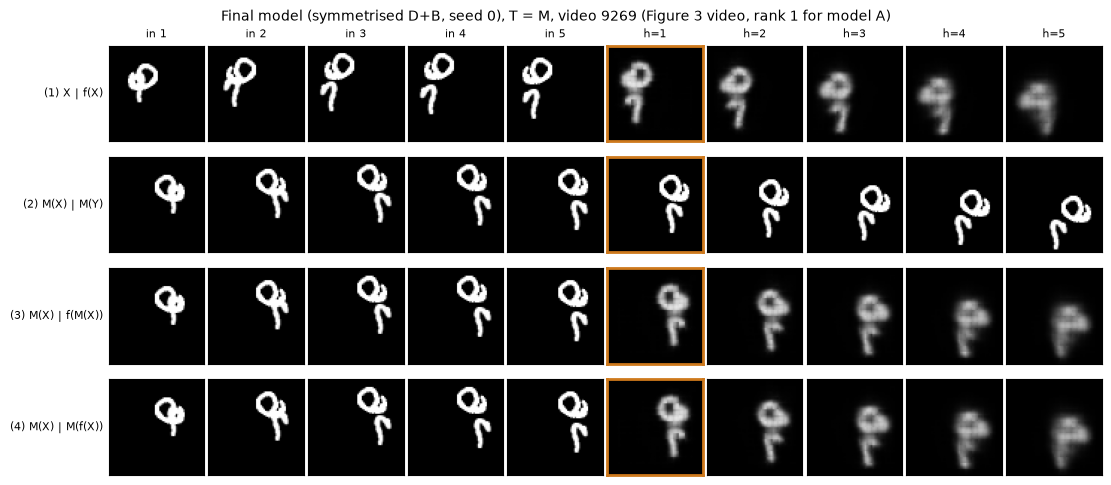

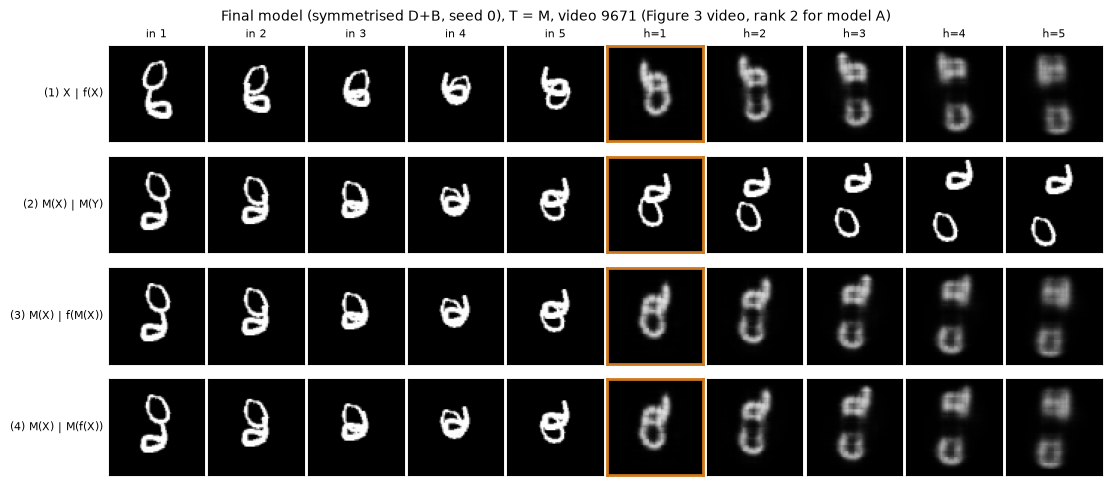

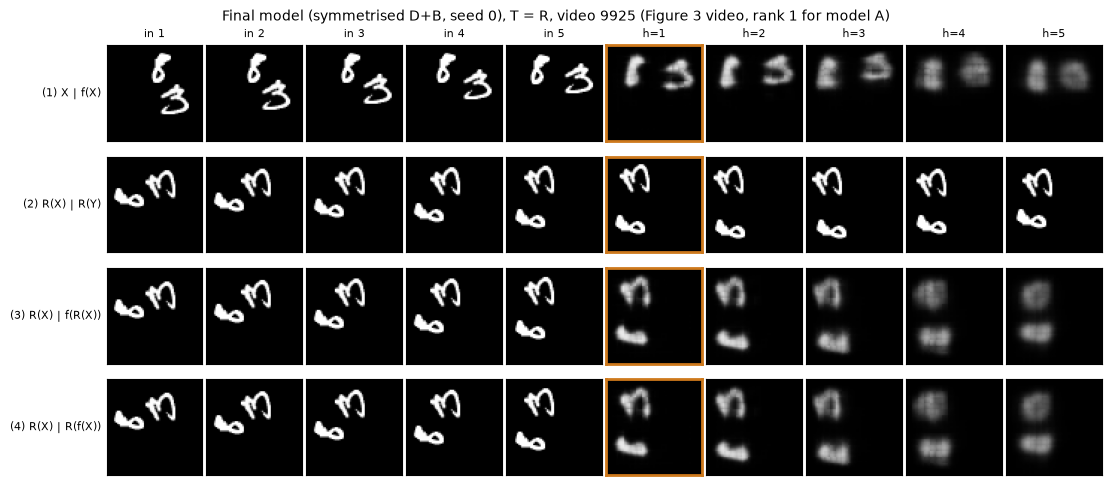

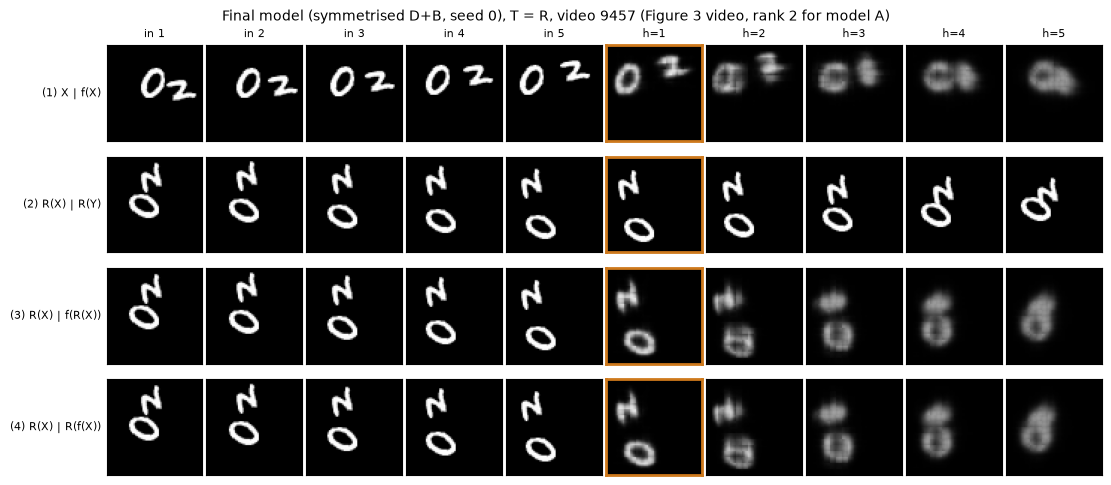

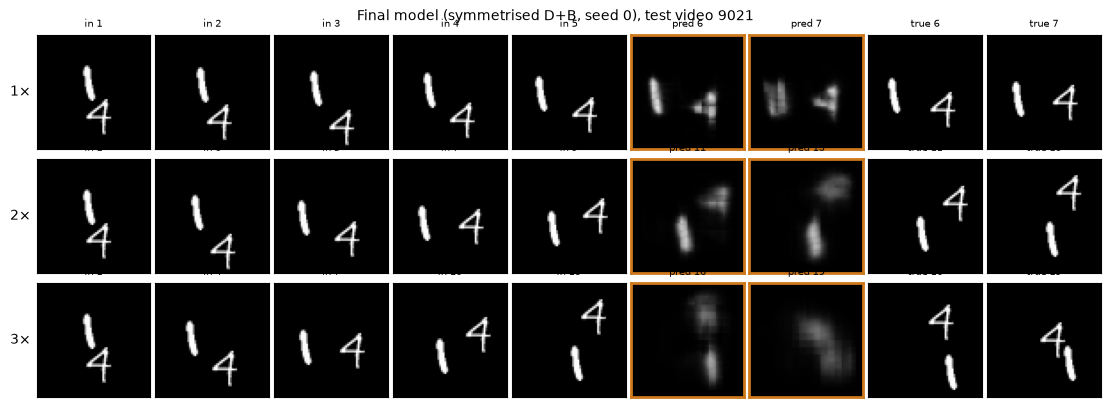

Figure 6 GIFs: ['./q2_outputs/gifs/fig6a_final_M_video9269.gif', './q2_outputs/gifs/fig6a_final_M_video9671.gif', './q2_outputs/gifs/fig6a_final_R_video9925.gif', './q2_outputs/gifs/fig6a_final_R_video9457.gif']


In [36]:
# Figure 6: (a) Figure 3 videos and (b) Figure 5 video with the final model (seed 0)
f_final = Symmetrised(load_model(FINAL, 0))
FIG3 = json.load(open(f"{OUT}/results/fig3_videos.json"))
FIG5 = json.load(open(f"{OUT}/results/fig5_video.json"))["video"]
fname = "symmetrised D+B" if FINAL == "DB" else "symmetrised D"
gif6 = []
for T_name, T in (("M", M), ("R", R)):
    for rank, i in enumerate(FIG3[T_name], 1):
        rows = four_rows(f_final, i, T)
        title = f"Final model ({fname}, seed 0), T = {T_name}, video {9000+i} (Figure 3 video, rank {rank} for model A)"
        save_panel(rows, ROW_LABELS[T_name], title, f"{OUT}/figures/fig6a_final_{T_name}_video{9000+i}.pdf")
        gp = f"{OUT}/gifs/fig6a_final_{T_name}_video{9000+i}.gif"
        save_gif(rows, ROW_LABELS[T_name], gp); gif6.append(gp)
save_speed_figure(speed_rows(f_final, FIG5), f"Final model ({fname}, seed 0), test video {9000+FIG5}",
                  f"{OUT}/figures/fig6b_final_speeds_video{9000+FIG5}.pdf")
print("Figure 6 GIFs:", gif6)